# Bitcoin-Volatilität: Forecasting mit Markt- und Sentimentdaten

In diesem Notebook entwickeln wir eine reproduzierbare Prognosepipeline für
die zukünftige realisierte Bitcoin-Volatilität. Wir laden BTC-USD,
Fear & Greed, VIX, DXY und Nasdaq, prüfen und synchronisieren die Daten ohne
Look-ahead Leakage, untersuchen die wichtigsten Muster und vergleichen
schrittweise einfache sowie fortgeschrittene Prognosemodelle.

**Primäres Ziel:** zukünftige realisierte Volatilität über sieben Tage.

Wir reservieren die Daten ab 2025 als unberührten finalen Holdout. Alle
Modellentscheidungen treffen wir vorher mit purged Walk-forward-Validierung.
Der aktuelle Stand enthält Datenaufbereitung, EDA, naive Baselines,
GARCH(1,1) und XGBoost mit vier Feature-Sets. Chronos-2 ergänzen wir im
nächsten Abschnitt desselben Notebooks.

## Kurzfassung

Wir erstellen eine tägliche Modelling-Tabelle ab 2018 und verwenden nur
vollständig abgeschlossene Bitcoin-Tageskerzen im UTC-Kalender. Externe
Variablen verschieben wir konservativ um einen Tag, wenn der genaue
Veröffentlichungszeitpunkt nicht sicher ist.

EDA und Modellentwicklung verwenden ausschliesslich den Zeitraum bis Ende
2024. Trainingszeilen, deren siebentägiges Zielfenster zum jeweiligen
Prognosezeitpunkt noch nicht abgeschlossen ist, werden entfernt. Auf 208
nicht überlappenden Prognosezeitpunkten vergleichen wir Persistenz, einen
gleitenden Mittelwert, GARCH(1,1) und vier XGBoost-Feature-Sets. Der finale
Holdout bleibt unberührt.

## 1. Setup

### Erklärung

Wir bündeln alle veränderbaren Parameter in einer Zelle. `DATA_END_DATE` ist
ein **exklusiver und fester UTC-Stichtag**: Der Datensatz endet somit am
18. Juli 2026, während der laufende UTC-Tag ausgeschlossen bleibt. Dadurch
erzeugen spätere Wiederholungen denselben historischen Ausschnitt.

Unser Prognosezeitpunkt liegt unmittelbar nach Abschluss der Bitcoin-UTC-
Tageskerze \(t\). Für spätere PyTorch-Modelle wählen wir auf Apple Silicon
automatisch `mps`, sofern es verfügbar ist. Die Datenaufbereitung läuft auf
der CPU.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import os
import platform
import random
import time
import warnings

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import yfinance as yf
from arch import arch_model
from xgboost import XGBRegressor

# Keep all configuration visible and reproducible
RANDOM_SEED = 42
START_DATE = "2018-02-01"
DATA_END_DATE = "2026-07-19"  # Exclusive UTC date; last included day is 2026-07-18
FORECAST_HORIZON = 7
FORECAST_TIMEZONE = "UTC"
HOLDOUT_START = pd.Timestamp("2025-01-01")
VALIDATION_YEARS = [2021, 2022, 2023, 2024]
EVALUATION_STEP_DAYS = 7
XGBOOST_N_JOBS = max(1, min(4, os.cpu_count() or 1))

# Refuse a cutoff that could include a still-running UTC candle
data_end_timestamp = pd.Timestamp(DATA_END_DATE)
current_utc_day = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
assert data_end_timestamp <= current_utc_day
last_included_date = data_end_timestamp - pd.Timedelta(days=1)

# Resolve paths whether Jupyter starts in the project root or notebooks folder
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Make random operations reproducible
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Use one consistent visual language throughout the notebook
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)
VIRIDIS = plt.colormaps["viridis"]
COLORS = {
    "btc": VIRIDIS(0.12),
    "volatility": VIRIDIS(0.38),
    "fear_greed": VIRIDIS(0.58),
    "vix": VIRIDIS(0.72),
    "dxy": VIRIDIS(0.84),
    "nasdaq": VIRIDIS(0.96),
}

# Detect MPS without moving pandas operations away from the CPU
try:
    import torch

    TORCH_VERSION = torch.__version__
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
except ImportError:
    torch = None
    TORCH_VERSION = "nicht installiert"
    DEVICE = "cpu"


def installed_version(package_name):
    '''Return a package version for the reproducibility table.'''
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "nicht installiert"


# Show the environment instead of hiding setup assumptions
environment_table = pd.DataFrame(
    {
        "Komponente": [
            "Python",
            "Betriebssystem",
            "Prozessor",
            "PyTorch",
            "Gewähltes Gerät",
            "Forecast-Zeitzone",
            "Letzter Datentag",
            "Holdout ab",
            "pandas",
            "yfinance",
            "arch",
            "XGBoost",
            "scikit-learn",
            "XGBoost CPU-Threads",
        ],
        "Wert": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            TORCH_VERSION,
            DEVICE,
            FORECAST_TIMEZONE,
            last_included_date.date(),
            HOLDOUT_START.date(),
            installed_version("pandas"),
            installed_version("yfinance"),
            installed_version("arch"),
            installed_version("xgboost"),
            installed_version("scikit-learn"),
            XGBOOST_N_JOBS,
        ],
    }
)
display(environment_table)

,Komponente,Wert
0,Python,3.11.13
1,Betriebssystem,macOS-26.5.2-arm64-arm-64bit
2,Prozessor,arm64
3,PyTorch,2.13.0
4,Gewähltes Gerät,mps
5,Forecast-Zeitzone,UTC
6,Letzter Datentag,2026-07-18
7,Holdout ab,2025-01-01
8,pandas,3.0.3
9,yfinance,1.5.1


### Interpretation

Wir verwenden einen festgelegten, vollständig abgeschlossenen Datenzeitraum.
MPS ist ausschliesslich für spätere PyTorch-Inferenz vorgesehen. pandas,
yfinance, GARCH und XGBoost bleiben auf der CPU. Die Tabelle dokumentiert
Stichtag, Holdout und tatsächlich verwendete Softwareumgebung.

## 2. Daten laden und prüfen

### Erklärung

Wir beziehen BTC-USD, VIX, DXY und Nasdaq über `yfinance`. Den Fear & Greed
Index laden wir über die öffentliche API von Alternative.me. Der Endzeitpunkt
von `yfinance.download()` ist exklusiv; `DATA_END_DATE = 2026-07-19` liefert
daher höchstens Daten bis zum abgeschlossenen UTC-Tag 18. Juli 2026.

Verwendete Yahoo-Symbole:

| Inhalt | Symbol |
|---|---|
| Bitcoin in USD | `BTC-USD` |
| VIX | `^VIX` |
| US-Dollar-Index | `DX-Y.NYB` |
| Nasdaq Composite | `^IXIC` |

Wir speichern die Rohdaten lokal. Ein Cache wird nur wiederverwendet, wenn er
nach Ende des letzten eingeschlossenen UTC-Tages erstellt wurde und sämtliche
Qualitätsregeln erfüllt. Andernfalls laden wir ihn neu.

In [2]:
YAHOO_SERIES = {
    "btc": {"ticker": "BTC-USD", "columns": ["Open", "High", "Low", "Close", "Volume"]},
    "vix": {"ticker": "^VIX", "columns": ["Close"]},
    "dxy": {"ticker": "DX-Y.NYB", "columns": ["Close"]},
    "nasdaq": {"ticker": "^IXIC", "columns": ["Close"]},
}


def validate_source_frame(frame, series_name):
    '''Validate chronology, completeness and stable domain rules.'''
    # Check the common daily-series contract first
    assert not frame.empty, f"{series_name}: keine Daten"
    assert frame.index.is_monotonic_increasing, f"{series_name}: Datum nicht sortiert"
    assert frame.index.is_unique, f"{series_name}: doppelte Datumswerte"
    expected_first_date = pd.Timestamp(START_DATE)
    expected_last_date = data_end_timestamp - pd.Timedelta(days=1)
    boundary_tolerance = pd.Timedelta(days=0 if series_name in {"btc", "fear_greed"} else 7)
    assert frame.index.min() >= expected_first_date, f"{series_name}: Datum vor Start"
    assert frame.index.min() <= expected_first_date + boundary_tolerance, (
        f"{series_name}: Quelle beginnt unerwartet spät"
    )
    assert frame.index.max() < data_end_timestamp, f"{series_name}: Datum nach Stichtag"
    assert frame.index.max() >= expected_last_date - boundary_tolerance, (
        f"{series_name}: Quelle endet unerwartet früh"
    )
    assert frame.notna().all().all(), f"{series_name}: fehlende Rohwerte"
    assert np.isfinite(frame.select_dtypes("number")).all().all(), f"{series_name}: nicht endliche Werte"

    if series_name == "btc":
        # Bitcoin must contain every UTC calendar day in the selected period
        expected_days = pd.date_range(frame.index.min(), frame.index.max(), freq="D")
        assert frame.index.equals(expected_days), "btc: fehlende oder zusätzliche Kalendertage"

        # Enforce basic OHLCV market-data identities
        price_columns = ["btc_open", "btc_high", "btc_low", "btc_close"]
        assert (frame[price_columns] > 0).all().all(), "btc: nicht positive Preise"
        assert (frame["btc_volume"] >= 0).all(), "btc: negatives Volumen"
        assert (
            frame["btc_high"] >= frame[["btc_open", "btc_close", "btc_low"]].max(axis=1)
        ).all(), "btc: High liegt unter Open, Close oder Low"
        assert (
            frame["btc_low"] <= frame[["btc_open", "btc_close", "btc_high"]].min(axis=1)
        ).all(), "btc: Low liegt über Open, Close oder High"

    if series_name == "fear_greed":
        assert frame["fear_greed"].between(0, 100).all(), "fear_greed: Wert ausserhalb 0-100"

    if series_name in {"vix", "dxy", "nasdaq"}:
        assert (frame.iloc[:, 0] > 0).all(), f"{series_name}: nicht positive Indexwerte"


def cache_is_usable(cache_path, frame, series_name):
    '''Return whether a cached extract is complete and valid.'''
    # A cache written before the exclusive cutoff may contain a running candle
    cache_written_utc = pd.Timestamp(cache_path.stat().st_mtime, unit="s", tz="UTC")
    cutoff_utc = pd.Timestamp(DATA_END_DATE, tz="UTC")
    if cache_written_utc < cutoff_utc:
        return False

    try:
        validate_source_frame(frame, series_name)
    except AssertionError:
        return False
    return True


def load_yahoo_series(series_name, ticker, columns):
    '''Load one Yahoo series from a validated cache or download it.'''
    # Include the date range in the cache name to keep extracts traceable
    safe_ticker = ticker.replace("^", "").replace("=", "_").replace(".", "_")
    cache_path = RAW_DATA_DIR / f"{series_name}_{safe_ticker}_{START_DATE}_{DATA_END_DATE}.csv"

    if cache_path.exists():
        # Reuse only a cache created after the final included candle closed
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        if cache_is_usable(cache_path, cached, series_name):
            return cached
        print(f"{series_name}: veralteter oder ungültiger Cache wird neu geladen.")

    # Download one ticker at a time to avoid unnecessary MultiIndex handling
    downloaded = yf.download(
        ticker,
        start=START_DATE,
        end=DATA_END_DATE,
        interval="1d",
        auto_adjust=False,
        repair=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
    if downloaded.empty:
        raise RuntimeError(f"Keine Yahoo-Daten für {ticker} erhalten.")

    # Interpret every daily index as a UTC calendar date
    downloaded.index = (
        pd.to_datetime(downloaded.index, utc=True).tz_convert(None).normalize()
    )
    downloaded.index.name = "date"
    frame = downloaded.loc[:, columns].copy()
    frame.columns = [f"{series_name}_{column.lower().replace(' ', '_')}" for column in columns]

    # Validate before replacing a stale cache
    validate_source_frame(frame, series_name)
    frame.reset_index().to_csv(cache_path, index=False)
    return frame


def load_fear_greed():
    '''Load the complete Fear & Greed history from cache or the public API.'''
    cache_path = RAW_DATA_DIR / f"fear_greed_{START_DATE}_{DATA_END_DATE}.csv"

    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        if cache_is_usable(cache_path, cached, "fear_greed"):
            return cached
        print("fear_greed: veralteter oder ungültiger Cache wird neu geladen.")

    # Request the full daily history in JSON format
    response = requests.get(
        "https://api.alternative.me/fng/",
        params={"limit": 0, "format": "json"},
        headers={"User-Agent": "CSP1 educational time-series project"},
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    assert "data" in payload and payload["data"], "Fear & Greed API ohne Daten"

    # Convert Unix timestamps explicitly from UTC into daily dates
    frame = pd.DataFrame(payload["data"])
    frame["date"] = (
        pd.to_datetime(frame["timestamp"].astype("int64"), unit="s", utc=True)
        .dt.tz_convert(None)
        .dt.normalize()
    )
    frame["fear_greed"] = pd.to_numeric(frame["value"], errors="coerce")
    frame = frame.set_index("date")[["fear_greed"]].sort_index()
    frame = frame.loc[(frame.index >= START_DATE) & (frame.index < DATA_END_DATE)]

    # Validate before replacing a stale cache
    validate_source_frame(frame, "fear_greed")
    frame.reset_index().to_csv(cache_path, index=False)
    return frame

In [3]:
# Download or reuse all requested market series
loaded_series = {
    name: load_yahoo_series(name, settings["ticker"], settings["columns"])
    for name, settings in YAHOO_SERIES.items()
}
loaded_series["fear_greed"] = load_fear_greed()

# Use explicit names for the following analysis steps
btc = loaded_series["btc"]
vix = loaded_series["vix"]
dxy = loaded_series["dxy"]
nasdaq = loaded_series["nasdaq"]
fear_greed = loaded_series["fear_greed"]

# Re-run every source contract visibly before the analysis
source_rows = []
for source_name, frame in loaded_series.items():
    validate_source_frame(frame, source_name)
    source_rows.append(
        {
            "Quelle": source_name,
            "Erster Tag": frame.index.min().date(),
            "Letzter Tag": frame.index.max().date(),
            "Zeilen": len(frame),
            "Doppelte Tage": int(frame.index.duplicated().sum()),
            "Fehlende Werte": int(frame.isna().sum().sum()),
            "Kalenderlücken": int(
                (frame.index.max() - frame.index.min()).days + 1 - len(frame)
            ),
            "Status": "bestanden",
        }
    )

source_summary = pd.DataFrame(source_rows)
display(source_summary)

# Show the latest Bitcoin rows so completed-candle checks remain inspectable
display(btc.tail(3).round(2))

,Quelle,Erster Tag,Letzter Tag,Zeilen,Doppelte Tage,Fehlende Werte,Kalenderlücken,Status
0,btc,2018-02-01,2026-07-18,3090,0,0,0,bestanden
1,vix,2018-02-01,2026-07-17,2126,0,0,963,bestanden
2,dxy,2018-02-01,2026-07-17,2127,0,0,962,bestanden
3,nasdaq,2018-02-01,2026-07-17,2125,0,0,964,bestanden
4,fear_greed,2018-02-01,2026-07-18,3086,0,0,4,bestanden


,btc_open,btc_high,btc_low,btc_close,btc_volume
date,,,,,
2026-07-16,64713.30,64931.86,63701.80,63789.28,27232426674
2026-07-17,63789.91,64332.02,62489.45,63899.46,27280236800
2026-07-18,63899.18,64816.50,63845.02,64796.60,14162542470


In [4]:
# Build the interpretation from observed and validated data
btc_days = len(btc)
calendar_days = (btc.index.max() - btc.index.min()).days + 1
coverage_ratio = btc_days / calendar_days
btc_days_display = f"{btc_days:,}".replace(",", "'")
fear_greed_calendar_gaps = int(
    source_summary.loc[
        source_summary["Quelle"] == "fear_greed", "Kalenderlücken"
    ].iloc[0]
)

display(
    Markdown(
        f'''
### Interpretation

Alle fünf Rohdatenquellen bestehen die Prüfungen auf zeitliche Abdeckung,
Chronologie, eindeutige Tage, fehlende und nicht endliche gespeicherte Werte
sowie ihre jeweiligen Wertebereiche. Für Bitcoin gelten zusätzlich die
OHLCV-Regeln. Wir verfügen über **{btc_days_display} vollständig
abgeschlossene Bitcoin-Tagesbeobachtungen** vom
**{btc.index.min().date()}** bis **{btc.index.max().date()}** bei einer
Kalenderabdeckung von {coverage_ratio:.1%}.

Die Spalte `Kalenderlücken` unterscheidet ausgelassene Daten von fehlenden
Werten innerhalb vorhandener Zeilen. Bei VIX, DXY und Nasdaq sind Wochenenden
und Feiertage erwartbar. Fear & Greed weist **{fear_greed_calendar_gaps}**
ausgelassene Kalendertage auf; diese Lücken behandeln wir im nächsten Schritt
explizit und nur mit begrenztem Forward-Fill.
'''
    )
)


### Interpretation

Alle fünf Rohdatenquellen bestehen die Prüfungen auf zeitliche Abdeckung,
Chronologie, eindeutige Tage, fehlende und nicht endliche gespeicherte Werte
sowie ihre jeweiligen Wertebereiche. Für Bitcoin gelten zusätzlich die
OHLCV-Regeln. Wir verfügen über **3'090 vollständig
abgeschlossene Bitcoin-Tagesbeobachtungen** vom
**2018-02-01** bis **2026-07-18** bei einer
Kalenderabdeckung von 100.0%.

Die Spalte `Kalenderlücken` unterscheidet ausgelassene Daten von fehlenden
Werten innerhalb vorhandener Zeilen. Bei VIX, DXY und Nasdaq sind Wochenenden
und Feiertage erwartbar. Fear & Greed weist **4**
ausgelassene Kalendertage auf; diese Lücken behandeln wir im nächsten Schritt
explizit und nur mit begrenztem Forward-Fill.


### Quellen und methodische Grundlagen

Wir verwenden öffentlich nachvollziehbare Datenquellen und dokumentieren die
methodischen Referenzen direkt im Notebook:

- [Yahoo Finance über yfinance](https://ranaroussi.github.io/yfinance/) für
  BTC-USD, VIX, DXY und Nasdaq.
- [Alternative.me Fear & Greed API](https://alternative.me/crypto/fear-and-greed-index/).
- Engle (1982), [ARCH](https://doi.org/10.2307/1912773), und Bollerslev
  (1986), [GARCH](https://doi.org/10.1016/0304-4076(86)90063-1).
- Chen und Guestrin (2016),
  [XGBoost](https://doi.org/10.1145/2939672.2939785).
- Hyndman und Athanasopoulos,
  [Forecasting: Principles and Practice](https://otexts.com/fpp3/).
- [Marco Peixeiro: Statistical forecasting baseline notebook](https://github.com/marcopeix/youtube_tutorials/blob/main/YT_03_forecasting_stats.ipynb).
- [MachineLearningMastery: 2026 Time Series Toolkit](https://machinelearningmastery.com/the-2026-time-series-toolkit-5-foundation-models-for-autonomous-forecasting/)
  als Überblick; für die spätere Implementierung verwenden wir die
  [offizielle Chronos-Dokumentation](https://github.com/amazon-science/chronos-forecasting).

Die Yahoo-Finance-Daten verwenden wir ausschliesslich für Ausbildung und
Forschung unter den jeweiligen Nutzungsbedingungen.

## 3. Daten zeitlich ausrichten

### Erklärung

Unser Prognoseursprung \(t\) liegt unmittelbar nach Abschluss der
Bitcoin-Tageskerze im UTC-Kalender. Bitcoin wird täglich gehandelt, die
traditionellen Märkte dagegen nur an Handelstagen. Wir verwenden deshalb den
Bitcoin-Kalender als Grundgerüst und tragen traditionelle Marktwerte höchstens
vier Kalendertage vorwärts.

Anschliessend verschieben wir **alle externen Variablen um einen Tag**. Damit
verwenden wir am Prognoseursprung nur Werte, die unabhängig vom exakten
Publikationszeitpunkt sicher verfügbar waren:

$$
x^{\mathrm{verwendet}}_t = x^{\mathrm{beobachtet}}_{t-1}
$$

Die Namen `fear_greed_lag_1` und ähnliche spätere Lags bezeichnen eine
zusätzliche Verzögerung relativ zu diesem bereits konservativ verfügbaren Wert.

In [5]:
# Join every source to the daily Bitcoin calendar
aligned = btc.join([fear_greed, vix, dxy, nasdaq], how="left")
external_columns = ["fear_greed", "vix_close", "dxy_close", "nasdaq_close"]

# Record missingness before calendar alignment
missing_before = aligned[external_columns].isna().sum()

# Fill only short calendar gaps caused by weekends and common holidays
aligned["fear_greed"] = aligned["fear_greed"].ffill(limit=2)
aligned[["vix_close", "dxy_close", "nasdaq_close"]] = aligned[
    ["vix_close", "dxy_close", "nasdaq_close"]
].ffill(limit=4)

# Shift external information by one day to enforce conservative availability
aligned[external_columns] = aligned[external_columns].shift(1)

# Keep remaining long gaps visible for later fold-specific preprocessing
missing_after = aligned[external_columns].isna().sum()
missing_table = pd.DataFrame(
    {
        "Vor Ausrichtung": missing_before,
        "Nach Füllen und Shift": missing_after,
        "Veränderung": missing_after - missing_before,
    }
)
display(missing_table)
display(aligned.head(5).round(2))

,Vor Ausrichtung,Nach Füllen und Shift,Veränderung
fear_greed,4,2,-2
vix_close,964,1,-963
dxy_close,963,1,-962
nasdaq_close,965,1,-964


,btc_open,btc_high,btc_low,btc_close,btc_volume,fear_greed,vix_close,dxy_close,nasdaq_close
date,,,,,,,,,
2018-02-01,10237.30,10288.80,8812.28,9170.54,9959400448,NaN,NaN,NaN,NaN
2018-02-02,9142.28,9142.28,7796.49,8830.75,12726899712,30.0,13.47,88.67,7385.86
2018-02-03,8852.12,9430.75,8251.63,9174.91,7263790080,15.0,17.31,89.20,7240.95
2018-02-04,9175.70,9334.87,8031.22,8277.01,7073549824,40.0,17.31,89.20,7240.95
2018-02-05,8270.54,8364.84,6756.68,6955.27,9285289984,24.0,17.31,89.20,7240.95


In [6]:
# Explain whether any long gaps remain after conservative alignment
remaining_missing = int(missing_after.sum())
affected_rows = int(aligned[external_columns].isna().any(axis=1).sum())

display(
    Markdown(
        f'''
### Interpretation

Nach der Ausrichtung verbleiben **{remaining_missing} fehlende externe
Einzelwerte** in **{affected_rows} Zeilen**. Dazu gehören mindestens die ersten
Beobachtungen, weil durch den Sicherheits-Shift noch kein Vortageswert
existiert. Wir löschen diese Zeilen erst nach dem Feature Engineering. Dadurch
bleibt jeder Datenverlust transparent und wir vermeiden eine globale
Interpolation über längere Lücken.
'''
    )
)


### Interpretation

Nach der Ausrichtung verbleiben **5 fehlende externe
Einzelwerte** in **2 Zeilen**. Dazu gehören mindestens die ersten
Beobachtungen, weil durch den Sicherheits-Shift noch kein Vortageswert
existiert. Wir löschen diese Zeilen erst nach dem Feature Engineering. Dadurch
bleibt jeder Datenverlust transparent und wir vermeiden eine globale
Interpolation über längere Lücken.


## 4. Zielvariable konstruieren

### Erklärung

Wir berechnen zuerst den logarithmischen Tagesreturn aus dem Bitcoin-Schlusskurs
\(P_t\):

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right)
$$

Die primäre Zielvariable ist die **zukünftige realisierte Volatilität über
sieben Tage**. Für einen Prognosezeitpunkt \(t\) verwenden wir ausschliesslich
die zukünftigen Returns \(t+1,\ldots,t+7\):

$$
\mathrm{RV}_{t,7} =
\sqrt{\sum_{i=1}^{7} r_{t+i}^{2}}
$$

Zum Vergleich berechnen wir auch die historische, rückwärts blickende
7-Tage-Volatilität. Sie ist am Tag \(t\) bekannt und darf später als Feature
oder naive Persistenzprognose verwendet werden.

In [7]:
# Calculate daily log returns from unadjusted Bitcoin close prices
aligned["btc_log_return"] = np.log(aligned["btc_close"] / aligned["btc_close"].shift(1))
aligned["btc_squared_return"] = aligned["btc_log_return"].pow(2)

# Create backward-looking realized volatility available at forecast time
aligned["rv_7"] = np.sqrt(
    aligned["btc_squared_return"].rolling(7, min_periods=7).sum()
)

# Reverse the shifted series so rolling sums look forward in original time
future_squared_returns = aligned["btc_squared_return"].shift(-1)
aligned["target_rv_7"] = np.sqrt(
    future_squared_returns.iloc[::-1]
    .rolling(FORECAST_HORIZON, min_periods=FORECAST_HORIZON)
    .sum()
    .iloc[::-1]
)

# Annualize only for reader-friendly plots, not for the model comparison
aligned["rv_7_annualized"] = aligned["rv_7"] * np.sqrt(365 / 7)
aligned["target_rv_7_annualized"] = aligned["target_rv_7"] * np.sqrt(365 / 7)

# Show observations with fully known historical and future windows
target_preview = aligned[
    ["btc_close", "btc_log_return", "rv_7", "target_rv_7"]
].dropna().tail(5)
display(target_preview.round(4))

,btc_close,btc_log_return,rv_7,target_rv_7
date,,,,
2026-07-07,63297.3945,-0.0110,0.0422,0.0561
2026-07-08,62257.5742,-0.0166,0.0382,0.0537
2026-07-09,63193.1484,0.0149,0.0329,0.0536
2026-07-10,64127.1406,0.0147,0.0318,0.0515
2026-07-11,63802.0273,-0.0051,0.0310,0.0532


In [8]:
# Recalculate every future target with an independent explicit loop
direct_targets = []
for position in range(len(aligned)):
    future_returns = aligned["btc_log_return"].iloc[
        position + 1 : position + 1 + FORECAST_HORIZON
    ]
    if len(future_returns) == FORECAST_HORIZON and future_returns.notna().all():
        direct_targets.append(np.sqrt(np.square(future_returns).sum()))
    else:
        direct_targets.append(np.nan)

direct_target_series = pd.Series(direct_targets, index=aligned.index)
comparison_mask = aligned["target_rv_7"].notna() & direct_target_series.notna()
target_differences = (
    aligned.loc[comparison_mask, "target_rv_7"]
    - direct_target_series.loc[comparison_mask]
).abs()

# Fail immediately if any target is shifted to the wrong date
max_target_difference = target_differences.max()
assert max_target_difference < 1e-12, "Die Zielvariable ist zeitlich falsch ausgerichtet."

target_check = pd.DataFrame(
    {
        "Prüfung": [
            "Verglichene Zielwerte",
            "Maximale absolute Differenz",
            "Erster gültiger Prognosetag",
            "Letzter gültiger Prognosetag",
        ],
        "Wert": [
            int(comparison_mask.sum()),
            max_target_difference,
            aligned.loc[comparison_mask].index.min().date(),
            aligned.loc[comparison_mask].index.max().date(),
        ],
    }
)
display(target_check)

,Prüfung,Wert
0,Verglichene Zielwerte,3083
1,Maximale absolute Differenz,0.0
2,Erster gültiger Prognosetag,2018-02-01
3,Letzter gültiger Prognosetag,2026-07-11


In [9]:
# Summarize only targets that end before the untouched holdout
development_target_mask = (
    aligned.index + pd.Timedelta(days=FORECAST_HORIZON) < HOLDOUT_START
)
development_targets = aligned.loc[development_target_mask, "target_rv_7"].dropna()
target_stats = development_targets.describe()
target_count_display = f"{int(comparison_mask.sum()):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Die unabhängige Kontrollrechnung stimmt für **{target_count_display}**
Zielwerte mit der vektorisierten Berechnung überein; die maximale Differenz
beträgt **{max_target_difference:.2e}**. Im Entwicklungszeitraum beträgt die
mediane nicht annualisierte 7-Tage-Volatilität **{target_stats['50%']:.3f}**,
das 90%-Quantil **{development_targets.quantile(0.90):.3f}**. Die letzten
sieben Zeilen des Gesamtdatensatzes besitzen definitionsgemäss noch kein
vollständiges zukünftiges Zielfenster.
'''
    )
)


### Interpretation

Die unabhängige Kontrollrechnung stimmt für **3'083**
Zielwerte mit der vektorisierten Berechnung überein; die maximale Differenz
beträgt **3.54e-15**. Im Entwicklungszeitraum beträgt die
mediane nicht annualisierte 7-Tage-Volatilität **0.071**,
das 90%-Quantil **0.135**. Die letzten
sieben Zeilen des Gesamtdatensatzes besitzen definitionsgemäss noch kein
vollständiges zukünftiges Zielfenster.


## 5. Features erzeugen

### Erklärung

Wir verwenden nur rückwärts blickende Merkmale. Dazu gehören Returns,
Handelsspanne, Volumen, rollierende historische Volatilität und verzögerte
Werte. Für VIX, DXY und Nasdaq berechnen wir Veränderungen auf den bereits um
einen Tag verschobenen Reihen.

Fear & Greed und das VIX-Niveau bleiben als interpretierbare Zustandsmerkmale
enthalten. Die stark trendenden absoluten DXY- und Nasdaq-Niveaus schliessen
wir aus dem Haupt-Feature-Set aus; ihre Returns und 7-/14-Tage-Veränderungen
bleiben enthalten. Eine spätere Skalierung oder Imputation muss innerhalb des
jeweiligen Trainingsfolds gelernt werden.

In [10]:
modeling_data = aligned.copy()

# Add simple Bitcoin features available at the end of each day
modeling_data["btc_abs_return"] = modeling_data["btc_log_return"].abs()
modeling_data["btc_high_low_range"] = (
    modeling_data["btc_high"] - modeling_data["btc_low"]
) / modeling_data["btc_close"]
modeling_data["btc_volume_log"] = np.log1p(modeling_data["btc_volume"])

# Add backward-looking volatility windows
for window in [14, 30]:
    modeling_data[f"rv_{window}"] = np.sqrt(
        modeling_data["btc_squared_return"].rolling(window, min_periods=window).sum()
    )

# Add explicit return and volatility lags
for lag in [1, 2, 3, 7, 14]:
    modeling_data[f"btc_log_return_lag_{lag}"] = modeling_data["btc_log_return"].shift(lag)
    modeling_data[f"rv_7_lag_{lag}"] = modeling_data["rv_7"].shift(lag)

# Calculate changes from already delayed external market levels
for column in ["vix_close", "dxy_close", "nasdaq_close"]:
    base_name = column.replace("_close", "")
    modeling_data[f"{base_name}_return_1d"] = modeling_data[column].pct_change(fill_method=None)
    modeling_data[f"{base_name}_change_7d"] = modeling_data[column].pct_change(
        periods=7, fill_method=None
    )
    modeling_data[f"{base_name}_change_14d"] = modeling_data[column].pct_change(
        periods=14, fill_method=None
    )

# Add sentiment lags and absolute changes
modeling_data["fear_greed_lag_1"] = modeling_data["fear_greed"].shift(1)
modeling_data["fear_greed_change_7d"] = modeling_data["fear_greed"].diff(7)
modeling_data["fear_greed_change_14d"] = modeling_data["fear_greed"].diff(14)

# Keep raw trending DXY and Nasdaq levels out of the main feature set
feature_columns = [
    "btc_log_return",
    "btc_abs_return",
    "btc_squared_return",
    "btc_high_low_range",
    "btc_volume_log",
    "rv_7",
    "rv_14",
    "rv_30",
    *[f"btc_log_return_lag_{lag}" for lag in [1, 2, 3, 7, 14]],
    *[f"rv_7_lag_{lag}" for lag in [1, 2, 3, 7, 14]],
    "fear_greed",
    "fear_greed_lag_1",
    "fear_greed_change_7d",
    "fear_greed_change_14d",
    "vix_close",
    "vix_return_1d",
    "vix_change_7d",
    "vix_change_14d",
    "dxy_return_1d",
    "dxy_change_7d",
    "dxy_change_14d",
    "nasdaq_return_1d",
    "nasdaq_change_7d",
    "nasdaq_change_14d",
]
target_columns = ["target_rv_7"]

# Remove only rows that cannot support the complete current feature set
modeling_table = modeling_data[feature_columns + target_columns].dropna().copy()
modeling_table["target_end"] = (
    modeling_table.index + pd.Timedelta(days=FORECAST_HORIZON)
)

# Purge development labels that reach the untouched holdout
development_table = modeling_table[
    modeling_table["target_end"] < HOLDOUT_START
].copy()
holdout_table = modeling_table[
    modeling_table.index >= HOLDOUT_START
].copy()
holdout_boundary_rows = modeling_table[
    (modeling_table.index < HOLDOUT_START)
    & (modeling_table["target_end"] >= HOLDOUT_START)
].copy()

# Save a reproducible table for later sections and external inspection
processed_path = PROCESSED_DATA_DIR / "bitcoin_volatility_modeling_table.csv"
modeling_table.to_csv(processed_path, index_label="date")

feature_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "Gesamte Beobachtungen",
            "Entwicklungsbeobachtungen",
            "Am Holdout-Rand gepurgte Beobachtungen",
            "Reservierte Holdout-Beobachtungen",
            "Features",
            "Erster Prognosetag",
            "Letzter Prognosetag",
            "Fehlende Werte",
        ],
        "Wert": [
            len(modeling_table),
            len(development_table),
            len(holdout_boundary_rows),
            len(holdout_table),
            len(feature_columns),
            modeling_table.index.min().date(),
            modeling_table.index.max().date(),
            int(modeling_table.isna().sum().sum()),
        ],
    }
)
display(feature_summary)

# Round only numeric columns so datetime metadata remains unchanged
development_preview = development_table.head(3).copy()
numeric_preview_columns = development_preview.select_dtypes("number").columns
development_preview[numeric_preview_columns] = development_preview[
    numeric_preview_columns
].round(4)
display(development_preview)

,Kennzahl,Wert
0,Gesamte Beobachtungen,3049
1,Entwicklungsbeobachtungen,2485
2,Am Holdout-Rand gepurgte Beobachtungen,7
3,Reservierte Holdout-Beobachtungen,557
4,Features,32
5,Erster Prognosetag,2018-03-03
6,Letzter Prognosetag,2026-07-11
7,Fehlende Werte,0


,btc_log_return,btc_abs_return,btc_squared_return,btc_high_low_range,btc_volume_log,rv_7,rv_14,rv_30,btc_log_return_lag_1,btc_log_return_lag_2,...,vix_change_7d,vix_change_14d,dxy_return_1d,dxy_change_7d,dxy_change_14d,nasdaq_return_1d,nasdaq_change_7d,nasdaq_change_14d,target_rv_7,target_end
date,,,,,,,,,,,,,,,,,,,,,
2018-03-03,0.0357,0.0357,0.0013,0.0458,22.6240,0.1067,0.1729,0.3613,0.0123,0.0518,...,0.188,0.0067,-0.0042,0.0007,0.0094,0.0108,-0.0108,0.0025,0.1321,2018-03-10
2018-03-04,0.0020,0.0020,0.0000,0.0327,22.5290,0.1056,0.1650,0.3594,0.0357,0.0123,...,0.188,0.0067,0.0000,0.0007,0.0094,0.0000,-0.0108,0.0025,0.1530,2018-03-11
2018-03-05,0.0053,0.0053,0.0000,0.0225,22.5902,0.0792,0.1531,0.3574,0.0020,0.0357,...,0.188,0.0067,0.0000,0.0007,0.0094,0.0000,-0.0108,0.0025,0.1580,2018-03-12


In [11]:
# Validate the final table and the development-holdout boundary
expected_last_target_date = aligned.index[-(FORECAST_HORIZON + 1)]
actual_last_target_date = modeling_table.index.max()
assert actual_last_target_date <= expected_last_target_date
assert modeling_table.index.is_unique
assert modeling_table.index.is_monotonic_increasing
assert modeling_table.drop(columns=["target_end"]).notna().all().all()
assert np.isfinite(
    modeling_table.drop(columns=["target_end"]).select_dtypes("number")
).all().all()
assert (development_table["target_end"] < HOLDOUT_START).all()
assert (holdout_boundary_rows["target_end"] >= HOLDOUT_START).all()
assert (holdout_table.index >= HOLDOUT_START).all()

modeling_rows_display = f"{len(modeling_table):,}".replace(",", "'")
development_rows_display = f"{len(development_table):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Die Modelling-Tabelle enthält **{modeling_rows_display} Beobachtungen** und
**{len(feature_columns)} Features** ohne fehlende oder unendliche Werte.
Davon stehen **{development_rows_display} Zeilen** für EDA und
Modellentwicklung zur Verfügung. Alle Entwicklungslabels enden vor dem
Holdout ab **{HOLDOUT_START.date()}**. Die
**{len(holdout_boundary_rows)} überlappenden Randzeilen** sind explizit
gepurgt. Die Holdout-Zielwerte werden in diesem Notebook weder analysiert noch
zur Feature-Auswahl verwendet.
'''
    )
)


### Interpretation

Die Modelling-Tabelle enthält **3'049 Beobachtungen** und
**32 Features** ohne fehlende oder unendliche Werte.
Davon stehen **2'485 Zeilen** für EDA und
Modellentwicklung zur Verfügung. Alle Entwicklungslabels enden vor dem
Holdout ab **2025-01-01**. Die
**7 überlappenden Randzeilen** sind explizit
gepurgt. Die Holdout-Zielwerte werden in diesem Notebook weder analysiert noch
zur Feature-Auswahl verwendet.


## 6. Explorative Datenanalyse

Alle EDA-Berechnungen verwenden ausschliesslich den Entwicklungszeitraum vor
dem finalen Holdout.

### 6.1 Bitcoin-Preis, Returns und Volatilität

#### Erklärung

Wir prüfen, ob die typischen Merkmale einer Finanzzeitreihe sichtbar sind:
ein nichtstationärer Preis, stark schwankende Returns und zeitlich gehäufte
Volatilitätsphasen. Für die Modellierung interessiert uns besonders, ob grosse
absolute Returns aufeinander folgen.

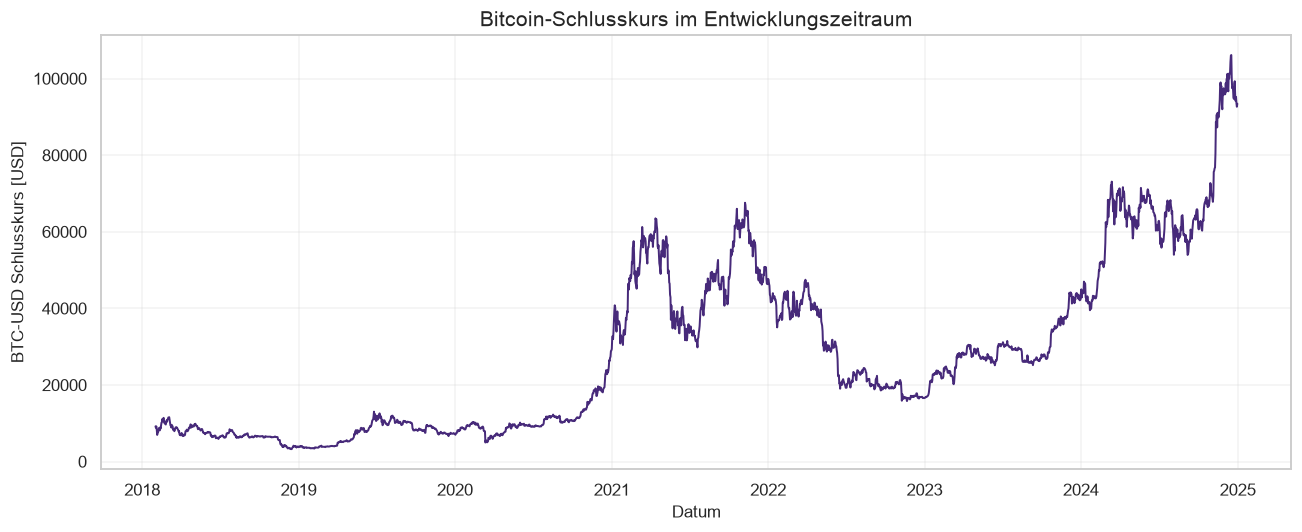

In [12]:
# Restrict all exploratory plots to the development period
eda_aligned = aligned.loc[aligned.index < HOLDOUT_START].copy()

# Plot the price separately because its scale differs from returns
fig, ax = plt.subplots()
ax.plot(eda_aligned.index, eda_aligned["btc_close"], color=COLORS["btc"], linewidth=1.3)
ax.set_title("Bitcoin-Schlusskurs im Entwicklungszeitraum")
ax.set_xlabel("Datum")
ax.set_ylabel("BTC-USD Schlusskurs [USD]")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

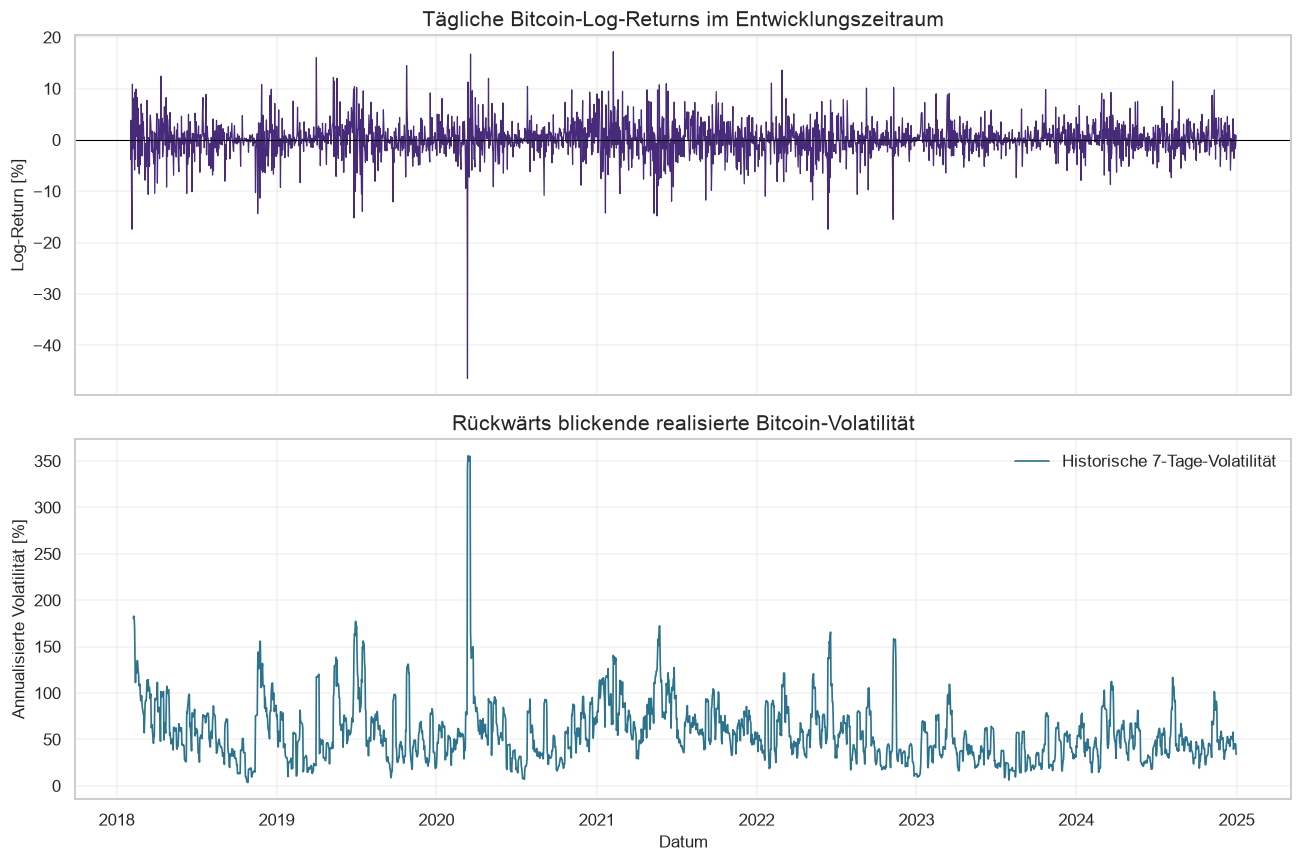

In [13]:
# Compare daily returns with backward-looking annualized volatility
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    eda_aligned.index,
    eda_aligned["btc_log_return"] * 100,
    color=COLORS["btc"],
    linewidth=0.8,
)
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Tägliche Bitcoin-Log-Returns im Entwicklungszeitraum")
axes[0].set_ylabel("Log-Return [%]")
axes[0].grid(alpha=0.25)

axes[1].plot(
    eda_aligned.index,
    eda_aligned["rv_7_annualized"] * 100,
    color=COLORS["volatility"],
    linewidth=1.1,
    label="Historische 7-Tage-Volatilität",
)
axes[1].set_title("Rückwärts blickende realisierte Bitcoin-Volatilität")
axes[1].set_xlabel("Datum")
axes[1].set_ylabel("Annualisierte Volatilität [%]")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

In [14]:
# Quantify volatility clustering only in the development period
abs_return_autocorrelation = development_table["btc_abs_return"].autocorr(lag=1)
peak_volatility_date = eda_aligned["rv_7_annualized"].idxmax()
peak_volatility = eda_aligned.loc[peak_volatility_date, "rv_7_annualized"] * 100

display(
    Markdown(
        f'''
#### Interpretation

Im Entwicklungszeitraum erkennen wir deutlich wechselnde Volatilitätsregime.
Die höchste rückwärts blickende annualisierte 7-Tage-Volatilität liegt am
**{peak_volatility_date.date()}** bei **{peak_volatility:.1f}%**. Die
Lag-1-Autokorrelation der absoluten Returns beträgt
**{abs_return_autocorrelation:.2f}**. Ein positiver Wert unterstützt die
Annahme von Volatilitätsclustering und damit den späteren Vergleich mit GARCH.
'''
    )
)


#### Interpretation

Im Entwicklungszeitraum erkennen wir deutlich wechselnde Volatilitätsregime.
Die höchste rückwärts blickende annualisierte 7-Tage-Volatilität liegt am
**2020-03-14** bei **355.7%**. Die
Lag-1-Autokorrelation der absoluten Returns beträgt
**0.14**. Ein positiver Wert unterstützt die
Annahme von Volatilitätsclustering und damit den späteren Vergleich mit GARCH.


### 6.2 Verteilung der Zielvariable

#### Erklärung

Wir betrachten die Verteilung von \(\mathrm{RV}_{t,7}\), weil starke
Rechtsschiefe und Ausreisser die Modellwahl und den Unterschied zwischen MAE
und RMSE beeinflussen. RMSE gewichtet grosse Fehler stärker als MAE.

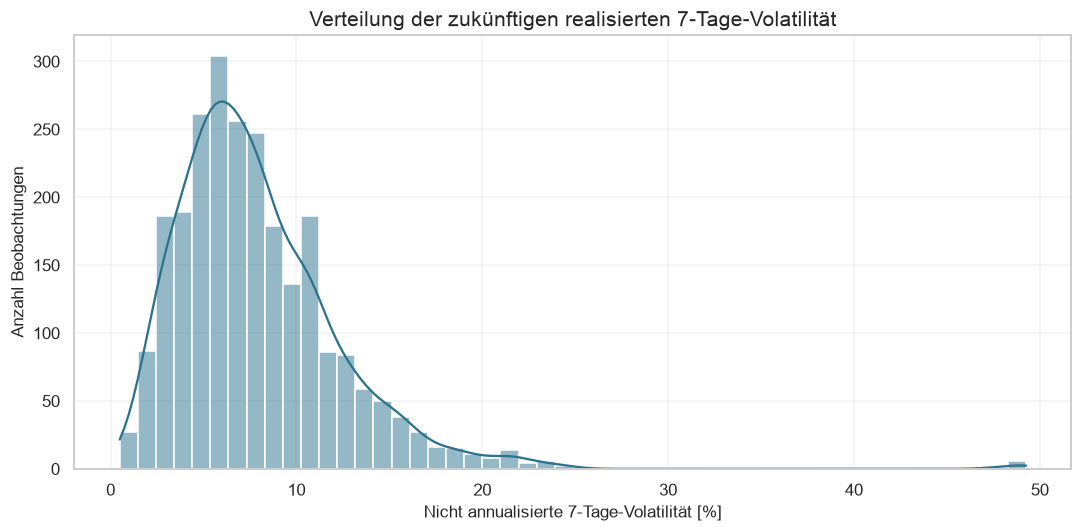

In [15]:
# Show the target distribution in percent without annualizing it
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    development_table["target_rv_7"] * 100,
    bins=50,
    kde=True,
    color=COLORS["volatility"],
    ax=ax,
)
ax.set_title("Verteilung der zukünftigen realisierten 7-Tage-Volatilität")
ax.set_xlabel("Nicht annualisierte 7-Tage-Volatilität [%]")
ax.set_ylabel("Anzahl Beobachtungen")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [16]:
# Compare the center and upper tail of the target distribution
target_quantiles = (
    development_table["target_rv_7"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .mul(100)
    .rename("7-Tage-Volatilität [%]")
    .to_frame()
)
display(target_quantiles.round(2))

distribution_skew = development_table["target_rv_7"].skew()
display(
    Markdown(
        f'''
#### Interpretation

Die Zielvariable ist mit einer Schiefe von **{distribution_skew:.2f}**
rechtsschief. Wir verwenden deshalb später sowohl MAE als robuste
Durchschnittsmetrik als auch RMSE, um besonders grosse Prognosefehler sichtbar
zu machen. Die Persistenz-Baseline bleibt wichtig, weil die Zielvariable
zeitlich geglättet und stark abhängig ist.
'''
    )
)

,7-Tage-Volatilität [%]
0.50,7.07
0.75,10.19
0.90,13.30
0.95,15.72
0.99,21.62



#### Interpretation

Die Zielvariable ist mit einer Schiefe von **2.63**
rechtsschief. Wir verwenden deshalb später sowohl MAE als robuste
Durchschnittsmetrik als auch RMSE, um besonders grosse Prognosefehler sichtbar
zu machen. Die Persistenz-Baseline bleibt wichtig, weil die Zielvariable
zeitlich geglättet und stark abhängig ist.


### 6.3 Externe Indikatoren und Bitcoin-Volatilität

#### Erklärung

Fear & Greed, VIX, DXY und Nasdaq haben unterschiedliche Einheiten. Für einen
rein visuellen Vergleich standardisieren wir die bereits verzögerten Niveaus
mit einem Z-Score:

$$
z_t = \frac{x_t-\bar{x}}{s_x}
$$

Wir berechnen Mittelwert und Standardabweichung ausschliesslich im
Entwicklungszeitraum. Diese Standardisierung dient nur der EDA; im späteren
Backtesting darf jede Transformation nur auf dem jeweiligen Trainingsfold
geschätzt werden.

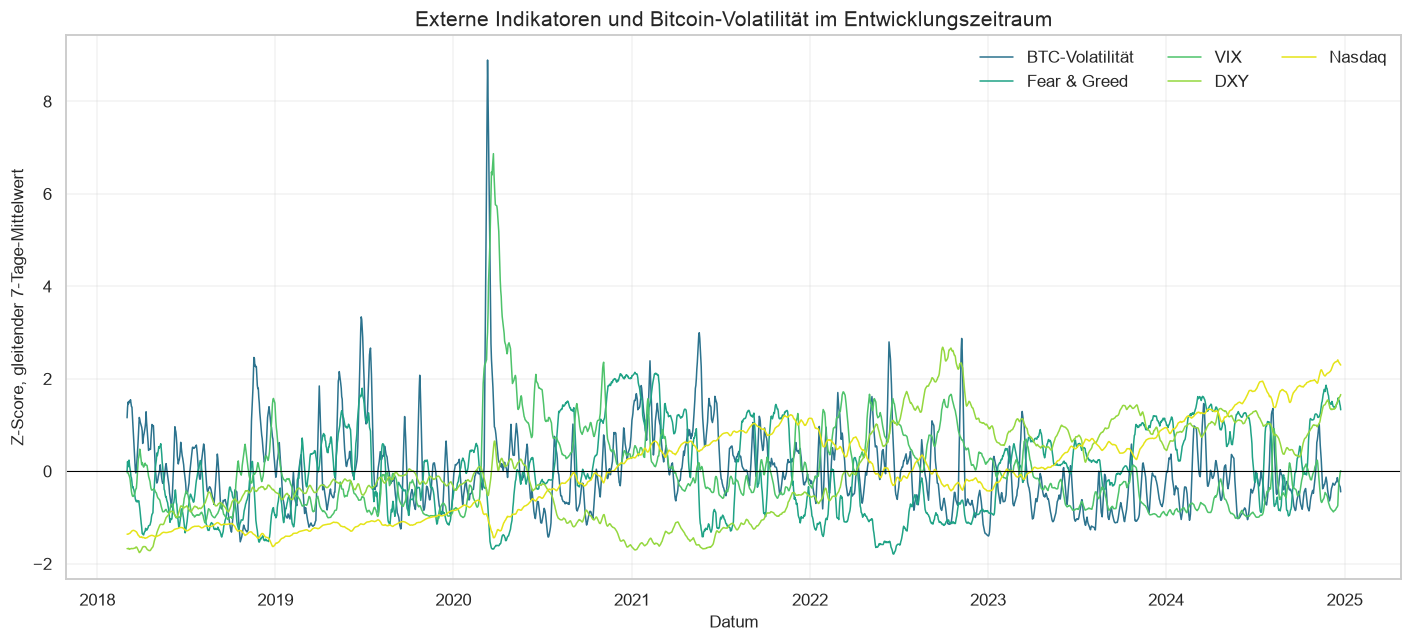

In [17]:
# Use only purged development dates for this exploratory comparison
comparison_levels = aligned.loc[
    development_table.index,
    [
        "target_rv_7_annualized",
        "fear_greed",
        "vix_close",
        "dxy_close",
        "nasdaq_close",
    ],
].dropna()
standardized_levels = (
    comparison_levels - comparison_levels.mean()
) / comparison_levels.std()

# Smooth visual noise without changing the modeling table
standardized_smoothed = standardized_levels.rolling(7, min_periods=1).mean()
display_names = {
    "target_rv_7_annualized": "BTC-Volatilität",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX",
    "dxy_close": "DXY",
    "nasdaq_close": "Nasdaq",
}
plot_colors = [
    COLORS["volatility"],
    COLORS["fear_greed"],
    COLORS["vix"],
    COLORS["dxy"],
    COLORS["nasdaq"],
]

fig, ax = plt.subplots(figsize=(13, 6))
for column, color in zip(standardized_smoothed.columns, plot_colors):
    ax.plot(
        standardized_smoothed.index,
        standardized_smoothed[column],
        label=display_names[column],
        color=color,
        linewidth=1.0,
    )
ax.axhline(0, color="black", linewidth=0.7)
ax.set_title("Externe Indikatoren und Bitcoin-Volatilität im Entwicklungszeitraum")
ax.set_xlabel("Datum")
ax.set_ylabel("Z-Score, gleitender 7-Tage-Mittelwert")
ax.legend(ncol=3)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### 6.4 Korrelationen mit der Zielvariable

#### Erklärung

Wir messen lineare Zusammenhänge mit der Pearson-Korrelation ausschliesslich
im Entwicklungszeitraum. Eine Korrelation beweist keine Kausalität und kann
sich zwischen Marktregimen verändern. Sie hilft uns aber, redundante Features
und erste Kandidaten für XGBoost zu erkennen, ohne den Holdout anzusehen.

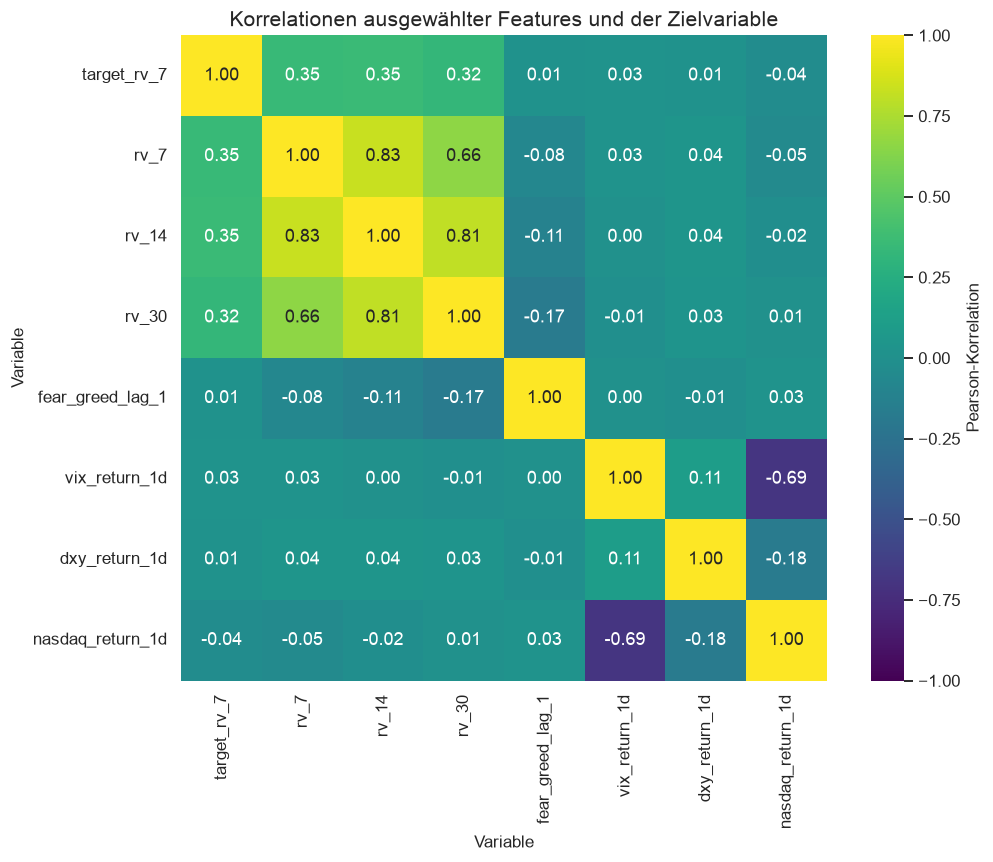

In [18]:
# Keep the heatmap compact and focused on interpretable feature groups
correlation_columns = [
    "target_rv_7",
    "rv_7",
    "rv_14",
    "rv_30",
    "fear_greed_lag_1",
    "vix_return_1d",
    "dxy_return_1d",
    "nasdaq_return_1d",
]
correlation_matrix = development_table[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Pearson-Korrelation"},
    ax=ax,
)
ax.set_title("Korrelationen ausgewählter Features und der Zielvariable")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
fig.tight_layout()
plt.show()

In [19]:
# Rank absolute correlations with the future volatility target
target_correlations = (
    correlation_matrix["target_rv_7"]
    .drop("target_rv_7")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
correlation_ranking = target_correlations.rename("Korrelation mit target_rv_7").to_frame()
display(correlation_ranking.round(3))

strongest_feature = target_correlations.index[0]
strongest_correlation = target_correlations.iloc[0]
display(
    Markdown(
        f'''
#### Interpretation

Unter den dargestellten Merkmalen weist **`{strongest_feature}`** mit
**{strongest_correlation:.2f}** den stärksten linearen Zusammenhang zur
zukünftigen 7-Tage-Volatilität auf. Wir erwarten, dass historische
Volatilitätsmerkmale wegen des Volatilitätsclusterings stärker korrelieren als
einzelne tägliche externe Returns. Ob Fear & Greed, VIX, DXY und Nasdaq
zusätzlichen Prognosewert liefern, prüfen wir später ausschliesslich mit
Walk-forward Backtesting.
'''
    )
)

,Korrelation mit target_rv_7
rv_14,0.353
rv_7,0.346
rv_30,0.324
nasdaq_return_1d,-0.038
vix_return_1d,0.028
fear_greed_lag_1,0.014
dxy_return_1d,0.009



#### Interpretation

Unter den dargestellten Merkmalen weist **`rv_14`** mit
**0.35** den stärksten linearen Zusammenhang zur
zukünftigen 7-Tage-Volatilität auf. Wir erwarten, dass historische
Volatilitätsmerkmale wegen des Volatilitätsclusterings stärker korrelieren als
einzelne tägliche externe Returns. Ob Fear & Greed, VIX, DXY und Nasdaq
zusätzlichen Prognosewert liefern, prüfen wir später ausschliesslich mit
Walk-forward Backtesting.


## 7. Übergabe an das purged Walk-forward-Backtesting

### Erklärung

Unsere Validierungsjahre sind 2021 bis 2024. Für einen Fold mit
Validierungsbeginn \(v\) entfernen wir jede Trainingszeile, deren
7-Tage-Zielfenster bis in die Validation reicht:

$$
t + h \geq v
$$

Die Modelle dürfen weiterhin auf allen verbleibenden täglichen Trainingszeilen
lernen. Für die Bewertung verwenden wir aber nur jeden siebten
Prognoseursprung. Dadurch überlappen sich die Evaluationsziele nicht.

Der Zeitraum ab 2025 bleibt vollständig ausserhalb dieser Folds und wird erst
nach Abschluss aller Modellentscheidungen einmalig ausgewertet.

In [20]:
# Build annual validation folds without touching the final holdout
fold_rows = []
evaluation_origins = {}

for validation_year in VALIDATION_YEARS:
    validation_start = pd.Timestamp(f"{validation_year}-01-01")
    validation_end = pd.Timestamp(f"{validation_year + 1}-01-01")

    # Purge every training label that reaches the validation period
    train_fold = development_table[
        development_table["target_end"] < validation_start
    ].copy()

    # Keep only validation targets fully contained in the validation year
    validation_candidates = development_table[
        (development_table.index >= validation_start)
        & (development_table["target_end"] < validation_end)
    ].copy()

    # Evaluate every seventh origin to avoid overlapping seven-day targets
    validation_origins = validation_candidates.index[::EVALUATION_STEP_DAYS]
    evaluation_origins[validation_year] = validation_origins

    # Validate the purge and spacing contracts
    assert not train_fold.empty
    assert not validation_origins.empty
    assert train_fold["target_end"].max() < validation_start
    if len(validation_origins) > 1:
        origin_spacing = pd.Series(validation_origins).diff().dropna().dt.days
        assert (origin_spacing >= FORECAST_HORIZON).all()

    fold_rows.append(
        {
            "Fold": f"Validation {validation_year}",
            "Training bis": train_fold.index.max().date(),
            "Letztes Trainingsziel endet": train_fold["target_end"].max().date(),
            "Validation von": validation_origins.min().date(),
            "Validation bis": validation_origins.max().date(),
            "Trainingszeilen": len(train_fold),
            "Evaluationsursprünge": len(validation_origins),
            "Purge bestanden": "ja",
        }
    )

fold_overview = pd.DataFrame(fold_rows)
display(fold_overview)

,Fold,Training bis,Letztes Trainingsziel endet,Validation von,Validation bis,Trainingszeilen,Evaluationsursprünge,Purge bestanden
0,Validation 2021,2020-12-24,2020-12-31,2021-01-01,2021-12-24,1024,52,ja
1,Validation 2022,2021-12-24,2021-12-31,2022-01-01,2022-12-24,1389,52,ja
2,Validation 2023,2022-12-24,2022-12-31,2023-01-01,2023-12-24,1754,52,ja
3,Validation 2024,2023-12-24,2023-12-31,2024-01-01,2024-12-23,2119,52,ja


In [21]:
# Summarize the fold handoff from executed checks
total_evaluation_origins = sum(len(origins) for origins in evaluation_origins.values())
first_holdout_origin = holdout_table.index.min()

display(
    Markdown(
        f'''
### Interpretation

Alle **{len(fold_overview)} Validierungsfolds** bestehen die Purge-Prüfung.
Insgesamt stehen **{total_evaluation_origins} nicht überlappende
Evaluationsursprünge** zur Verfügung. Der Holdout beginnt am
**{first_holdout_origin.date()}** und ist in keinem Validierungsfold enthalten.

Für Chronos-2 verwenden wir später die bis \(t\) beobachtete rückwärts
blickende Reihe `rv_7`, prognostizieren sieben Schritte und nehmen Schritt 7:

$$
\widehat{{\mathrm{{target\_rv7}}}}_t
=
\widehat{{\mathrm{{rv7}}}}_{{t+7}}
$$

Die forward-looking Reihe `target_rv_7` darf niemals als am Tag \(t\)
verfügbarer Chronos-Kontext verwendet werden.
'''
    )
)


### Interpretation

Alle **4 Validierungsfolds** bestehen die Purge-Prüfung.
Insgesamt stehen **208 nicht überlappende
Evaluationsursprünge** zur Verfügung. Der Holdout beginnt am
**2025-01-01** und ist in keinem Validierungsfold enthalten.

Für Chronos-2 verwenden wir später die bis \(t\) beobachtete rückwärts
blickende Reihe `rv_7`, prognostizieren sieben Schritte und nehmen Schritt 7:

$$
\widehat{\mathrm{target\_rv7}}_t
=
\widehat{\mathrm{rv7}}_{t+7}
$$

Die forward-looking Reihe `target_rv_7` darf niemals als am Tag \(t\)
verfügbarer Chronos-Kontext verwendet werden.


## 8. Modellvergleich: Baselines und GARCH

### 8.1 Bewertungsmetriken

#### Erklärung

Wir verwenden drei komplementäre Fehlermasse. MAE misst den durchschnittlichen
absoluten Fehler und reagiert relativ robust auf einzelne Extremtage:

$$
\mathrm{MAE}
=
\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

RMSE gewichtet grosse Fehler stärker:

$$
\mathrm{RMSE}
=
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

Für Volatilitätsprognosen ergänzen wir QLIKE. Wir vergleichen dabei
realisierte und prognostizierte Varianz. Ein perfekter Forecast hat den Wert
null; kleinere Werte sind besser:

$$
\mathrm{QLIKE}
=
\frac{1}{n}\sum_{i=1}^{n}
\left(
\frac{y_i^2}{\hat{y}_i^2}
- \log\left(\frac{y_i^2}{\hat{y}_i^2}\right)
- 1
\right)
$$

Alle Modelle werden auf exakt denselben 208 nicht überlappenden
Prognoseursprüngen beurteilt.

In [22]:
def mean_absolute_error(y_true, y_pred):
    '''Return the mean absolute forecast error.'''
    true_values = np.asarray(y_true, dtype=float)
    predicted_values = np.asarray(y_pred, dtype=float)
    return np.mean(np.abs(true_values - predicted_values))


def root_mean_squared_error(y_true, y_pred):
    '''Return the root mean squared forecast error.'''
    true_values = np.asarray(y_true, dtype=float)
    predicted_values = np.asarray(y_pred, dtype=float)
    return np.sqrt(np.mean(np.square(true_values - predicted_values)))


def qlike_loss(y_true, y_pred, epsilon=1e-12):
    '''Return normalized QLIKE on realized and predicted volatility.'''
    true_variance = np.maximum(np.square(np.asarray(y_true, dtype=float)), epsilon)
    predicted_variance = np.maximum(
        np.square(np.asarray(y_pred, dtype=float)),
        epsilon,
    )
    variance_ratio = true_variance / predicted_variance
    return np.mean(variance_ratio - np.log(variance_ratio) - 1)


# Verify metric behavior with transparent deterministic examples
metric_test_actual = np.array([1.0, 2.0])
metric_test_forecast = np.array([1.0, 4.0])
assert np.isclose(mean_absolute_error(metric_test_actual, metric_test_forecast), 1.0)
assert np.isclose(
    root_mean_squared_error(metric_test_actual, metric_test_forecast),
    np.sqrt(2),
)
assert np.isclose(qlike_loss(metric_test_actual, metric_test_actual), 0.0)

metric_check = pd.DataFrame(
    {
        "Metrik": ["MAE", "RMSE", "QLIKE"],
        "Prüfergebnis": ["bestanden", "bestanden", "bestanden"],
        "Optimale Richtung": ["kleiner", "kleiner", "kleiner"],
    }
)
display(metric_check)

,Metrik,Prüfergebnis,Optimale Richtung
0,MAE,bestanden,kleiner
1,RMSE,bestanden,kleiner
2,QLIKE,bestanden,kleiner


#### Interpretation

Die drei Implementierungen bestehen einfache, deterministische Selbsttests.
MAE und RMSE bleiben auf derselben Skala wie unsere nicht annualisierte
7-Tage-Volatilität. In den Ergebnistabellen stellen wir sie zur besseren
Lesbarkeit in Prozentpunkten dar. QLIKE ist dimensionslos.

### 8.2 Naive Baselines

#### Erklärung

Komplexere Modelle müssen mindestens einfache, zum Prognosezeitpunkt
verfügbare Regeln schlagen.

Die **Persistenz-Baseline** setzt die zukünftige 7-Tage-Volatilität gleich der
am Tag \(t\) beobachteten rückwärts blickenden 7-Tage-Volatilität:

$$
\hat{y}_{t}^{\mathrm{Persistenz}} = \mathrm{RV}_{t-6:t}
$$

Die **30-Tage-Mittelwert-Baseline** glättet die letzten 30 beobachteten
7-Tage-Volatilitäten:

$$
\hat{y}_{t}^{\mathrm{Mittelwert}}
=
\frac{1}{30}\sum_{j=0}^{29}\mathrm{RV}_{t-j}
$$

Beide Regeln benötigen kein Training und verwenden keine Information nach
dem jeweiligen Prognoseursprung.

In [23]:
# Create baseline forecasts at the predefined non-overlapping origins
prediction_rows = []
for validation_year, origins in evaluation_origins.items():
    for origin in origins:
        observed_rv_history = development_table.loc[:origin, "rv_7"].dropna()
        assert len(observed_rv_history) >= 30

        prediction_rows.append(
            {
                "date": origin,
                "fold": f"Validation {validation_year}",
                "actual": development_table.loc[origin, "target_rv_7"],
                "Persistenz": observed_rv_history.iloc[-1],
                "30-Tage-Mittelwert": observed_rv_history.tail(30).mean(),
            }
        )

prediction_table = pd.DataFrame(prediction_rows).set_index("date").sort_index()

# Enforce a common evaluation sample for every model
assert len(prediction_table) == total_evaluation_origins
assert prediction_table.index.max() < HOLDOUT_START
assert prediction_table.notna().all().all()

display(prediction_table.head(5).round(4))

,fold,actual,Persistenz,30-Tage-Mittelwert
date,,,,
2021-01-01,Validation 2021,0.1580,0.0941,0.0933
2021-01-08,Validation 2021,0.1606,0.1580,0.1027
2021-01-15,Validation 2021,0.1625,0.1606,0.1213
2021-01-22,Validation 2021,0.1232,0.1625,0.1262
2021-01-29,Validation 2021,0.0936,0.1232,0.1409


#### Interpretation

Die Baseline-Tabelle enthält für jeden vorab definierten Prognoseursprung
genau einen tatsächlichen Zielwert und zwei Prognosen. Ihre Zeilen enden vor
dem Holdout. Damit steht eine feste Vergleichsbasis für GARCH und die späteren
Modelle bereit.

### 8.3 GARCH(1,1)

#### Erklärung

GARCH modelliert die bedingte tägliche Return-Varianz. Für GARCH(1,1) gilt:

$$
\sigma_t^2
=
\omega
+ \alpha\epsilon_{t-1}^2
+ \beta\sigma_{t-1}^2
$$

\(\epsilon_{t-1}^2\) repräsentiert den letzten Volatilitätsschock,
\(\sigma_{t-1}^2\) die vorherige bedingte Varianz. Wir schätzen ein Modell mit
Normalverteilung und Mittelwert null, weil der tägliche erwartete
Bitcoin-Return im Verhältnis zur Volatilität klein ist.

An jedem Evaluationsursprung \(t\) schätzen wir GARCH neu mit allen bis
einschliesslich \(t\) beobachteten Returns. Die sieben prognostizierten
Tagesvarianzen werden auf dieselbe Skala wie unser Ziel aggregiert:

$$
\widehat{\mathrm{RV}}_{t+1:t+7}
=
\sqrt{\sum_{k=1}^{7}\hat{\sigma}_{t+k|t}^{2}}
$$

Für numerische Stabilität wird GARCH mit Returns in Prozent geschätzt; die
aggregierte Prognose rechnen wir anschliessend zurück in Dezimalwerte.

In [24]:
def forecast_garch_realized_volatility(return_history, horizon):
    '''Fit GARCH(1,1) and aggregate daily variance forecasts to the target scale.'''
    # Scale returns to percent for stable numerical optimization
    returns_percent = return_history.dropna().astype(float) * 100
    assert len(returns_percent) >= 250

    model = arch_model(
        returns_percent,
        mean="Zero",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False,
    )

    # Keep warnings inspectable through the convergence flag instead of noisy output
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted_model = model.fit(disp="off", show_warning=False)

    daily_variance_forecast = (
        fitted_model.forecast(
            horizon=horizon,
            method="analytic",
            reindex=False,
        )
        .variance.iloc[-1]
        .to_numpy(dtype=float)
    )

    # Sum forecasted percent-squared variances and convert back to decimal volatility
    forecast = np.sqrt(np.clip(daily_variance_forecast, 0, None).sum()) / 100
    return forecast, int(fitted_model.convergence_flag)


# Refit at each origin so the model uses every return observed by that date
garch_forecasts = []
garch_convergence_flags = []
garch_start_time = time.perf_counter()

for origin in prediction_table.index:
    available_returns = aligned.loc[:origin, "btc_log_return"]
    forecast, convergence_flag = forecast_garch_realized_volatility(
        available_returns,
        FORECAST_HORIZON,
    )
    garch_forecasts.append(forecast)
    garch_convergence_flags.append(convergence_flag)

garch_runtime_seconds = time.perf_counter() - garch_start_time
prediction_table["GARCH(1,1)"] = garch_forecasts

# Stop if optimization or forecast construction produced an invalid result
assert np.isfinite(prediction_table["GARCH(1,1)"]).all()
assert (prediction_table["GARCH(1,1)"] > 0).all()

garch_run_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "GARCH-Schätzungen",
            "Erfolgreich konvergiert",
            "Nicht konvergiert",
            "Laufzeit [s]",
        ],
        "Wert": [
            len(garch_forecasts),
            int(np.sum(np.asarray(garch_convergence_flags) == 0)),
            int(np.sum(np.asarray(garch_convergence_flags) != 0)),
            round(garch_runtime_seconds, 1),
        ],
    }
)
display(garch_run_summary)

,Kennzahl,Wert
0,GARCH-Schätzungen,208.0
1,Erfolgreich konvergiert,208.0
2,Nicht konvergiert,0.0
3,Laufzeit [s],1.2


In [25]:
# Summarize GARCH scale and convergence without inspecting the holdout
garch_scale_table = prediction_table[
    ["actual", "Persistenz", "30-Tage-Mittelwert", "GARCH(1,1)"]
].describe(percentiles=[0.1, 0.5, 0.9]).T
garch_scale_table = garch_scale_table[
    ["count", "mean", "std", "10%", "50%", "90%", "min", "max"]
]

# Convert volatility columns to percent while preserving the observation count
garch_scale_display = garch_scale_table.copy()
scale_columns = ["mean", "std", "10%", "50%", "90%", "min", "max"]
garch_scale_display[scale_columns] = garch_scale_display[scale_columns] * 100
garch_scale_display["count"] = garch_scale_display["count"].astype(int)
display(garch_scale_display.round(2).rename_axis("Reihe"))

,count,mean,std,10%,50%,90%,min,max
Reihe,,,,,,,,
actual,208,7.63,3.92,3.22,6.89,12.95,1.57,22.35
Persistenz,208,7.65,3.91,3.22,6.92,12.95,1.57,22.35
30-Tage-Mittelwert,208,7.69,2.71,4.40,7.44,11.16,2.94,15.54
"GARCH(1,1)",208,9.43,1.66,7.68,9.05,11.50,7.19,17.10


#### Interpretation

Die Konvergenztabelle zeigt, ob jede GARCH-Schätzung numerisch erfolgreich
war. Die anschliessende Übersicht vergleicht die Grössenordnung der
Prognosen mit der Zielvariable in Prozent. Dadurch erkennen wir vor der
Bewertung sofort grobe Skalierungsfehler.

### 8.4 Ergebnisse

#### Erklärung

Wir berechnen die drei Metriken zunächst gemeinsam über alle
Evaluationsursprünge und danach separat pro Validierungsjahr. Zusätzlich
berichten wir die relative MAE-Verbesserung gegenüber Persistenz:

$$
\mathrm{Verbesserung}
=
1-\frac{\mathrm{MAE}_{Modell}}{\mathrm{MAE}_{Persistenz}}
$$

Positive Werte bedeuten eine Verbesserung, negative Werte eine
Verschlechterung.

In [26]:
model_columns = ["Persistenz", "30-Tage-Mittelwert", "GARCH(1,1)"]


def calculate_metric_row(frame, model_name, fold_name="Alle Folds"):
    '''Calculate all point-forecast metrics for one model and sample.'''
    actual = frame["actual"].to_numpy()
    forecast = frame[model_name].to_numpy()
    return {
        "Fold": fold_name,
        "Modell": model_name,
        "Beobachtungen": len(frame),
        "MAE": mean_absolute_error(actual, forecast),
        "RMSE": root_mean_squared_error(actual, forecast),
        "QLIKE": qlike_loss(actual, forecast),
    }


# Calculate pooled metrics over exactly the same validation origins
overall_metric_rows = [
    calculate_metric_row(prediction_table, model_name)
    for model_name in model_columns
]
overall_metrics = pd.DataFrame(overall_metric_rows)

naive_mae = overall_metrics.loc[
    overall_metrics["Modell"] == "Persistenz",
    "MAE",
].iloc[0]
overall_metrics["MAE-Verbesserung ggü. Persistenz"] = (
    1 - overall_metrics["MAE"] / naive_mae
)
overall_metrics = overall_metrics.sort_values("MAE").reset_index(drop=True)

# Keep a display copy so internal calculations remain in decimal units
overall_metrics_display = overall_metrics.copy()
overall_metrics_display["MAE [%P]"] = overall_metrics_display["MAE"] * 100
overall_metrics_display["RMSE [%P]"] = overall_metrics_display["RMSE"] * 100
overall_metrics_display["MAE-Verbesserung [%]"] = (
    overall_metrics_display["MAE-Verbesserung ggü. Persistenz"] * 100
)
display(
    overall_metrics_display[
        [
            "Modell",
            "Beobachtungen",
            "MAE [%P]",
            "RMSE [%P]",
            "QLIKE",
            "MAE-Verbesserung [%]",
        ]
    ].round(3)
)

,Modell,Beobachtungen,MAE [%P],RMSE [%P],QLIKE,MAE-Verbesserung [%]
0,30-Tage-Mittelwert,208,2.825,3.706,0.607,13.732
1,"GARCH(1,1)",208,3.267,3.946,0.443,0.231
2,Persistenz,208,3.275,4.377,0.998,0.000


In [27]:
# Compare the same models separately in every validation year
fold_metric_rows = []
for fold_name, fold_predictions in prediction_table.groupby("fold", sort=True):
    for model_name in model_columns:
        fold_metric_rows.append(
            calculate_metric_row(fold_predictions, model_name, fold_name)
        )

fold_metrics = pd.DataFrame(fold_metric_rows)
fold_metrics_display = fold_metrics.copy()
fold_metrics_display["MAE [%P]"] = fold_metrics_display["MAE"] * 100
fold_metrics_display["RMSE [%P]"] = fold_metrics_display["RMSE"] * 100
display(
    fold_metrics_display[
        ["Fold", "Modell", "Beobachtungen", "MAE [%P]", "RMSE [%P]", "QLIKE"]
    ].round(3)
)

,Fold,Modell,Beobachtungen,MAE [%P],RMSE [%P],QLIKE
0,Validation 2021,Persistenz,52,3.083,3.899,0.352
1,Validation 2021,30-Tage-Mittelwert,52,3.045,3.764,0.262
2,Validation 2021,"GARCH(1,1)",52,2.767,3.417,0.202
3,Validation 2022,Persistenz,52,4.287,5.817,1.165
4,Validation 2022,30-Tage-Mittelwert,52,3.537,4.685,0.955
5,Validation 2022,"GARCH(1,1)",52,3.918,4.846,0.577
6,Validation 2023,Persistenz,52,2.998,3.673,1.777
7,Validation 2023,30-Tage-Mittelwert,52,2.306,2.901,0.708
8,Validation 2023,"GARCH(1,1)",52,3.489,3.953,0.633
9,Validation 2024,Persistenz,52,2.730,3.756,0.697


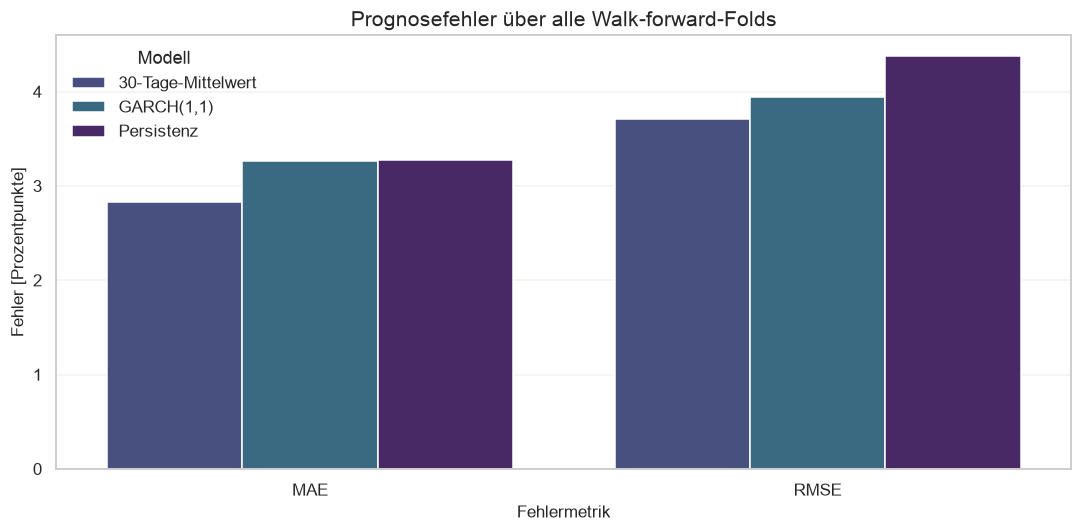

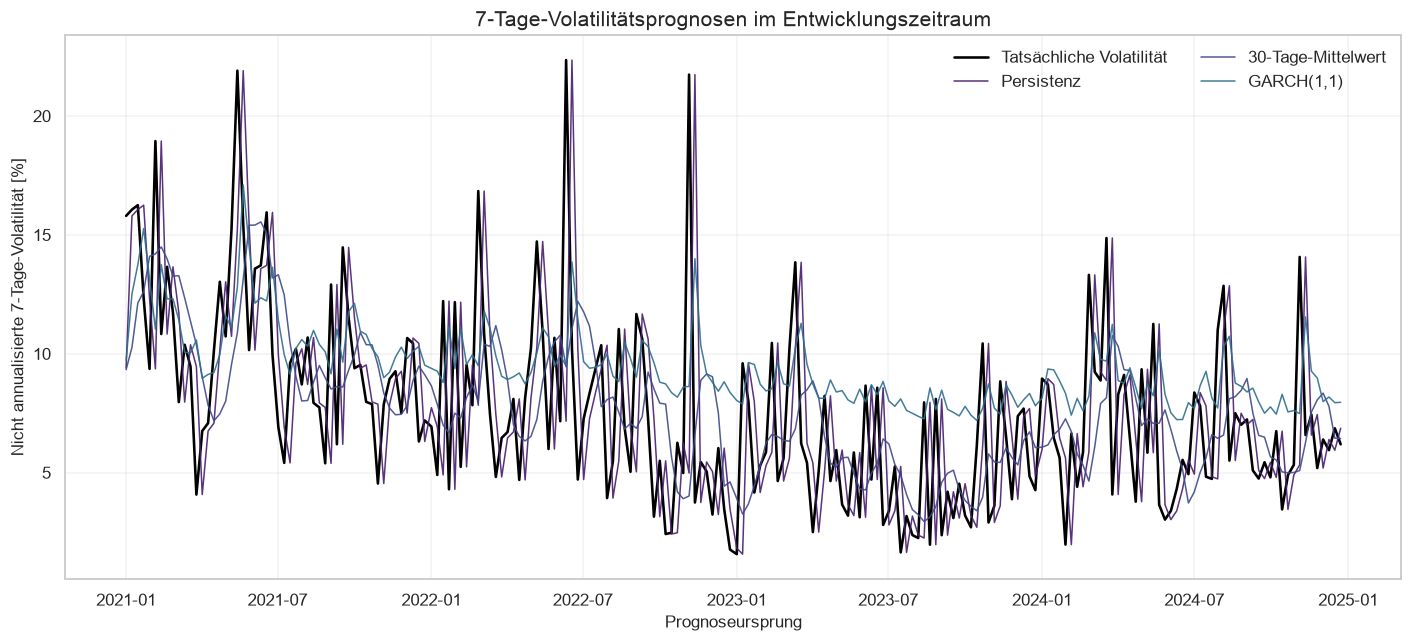

In [28]:
# Plot MAE and RMSE in percentage points with consistent model colors
metric_plot_data = overall_metrics.melt(
    id_vars="Modell",
    value_vars=["MAE", "RMSE"],
    var_name="Metrik",
    value_name="Fehler",
)
metric_plot_data["Fehler [%P]"] = metric_plot_data["Fehler"] * 100
model_palette = {
    "Persistenz": VIRIDIS(0.08),
    "30-Tage-Mittelwert": VIRIDIS(0.22),
    "GARCH(1,1)": VIRIDIS(0.36),
    "XGBoost A: BTC": VIRIDIS(0.50),
    "XGBoost B: BTC + Sentiment": VIRIDIS(0.64),
    "XGBoost C: BTC + Markt": VIRIDIS(0.78),
    "XGBoost D: Kombiniert": VIRIDIS(0.92),
}

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=metric_plot_data,
    x="Metrik",
    y="Fehler [%P]",
    hue="Modell",
    palette=model_palette,
    ax=ax,
)
ax.set_title("Prognosefehler über alle Walk-forward-Folds")
ax.set_xlabel("Fehlermetrik")
ax.set_ylabel("Fehler [Prozentpunkte]")
ax.legend(title="Modell")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# Show forecast behavior through time on the fixed evaluation origins
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(
    prediction_table.index,
    prediction_table["actual"] * 100,
    color="black",
    linewidth=1.7,
    label="Tatsächliche Volatilität",
)
for model_name in model_columns:
    ax.plot(
        prediction_table.index,
        prediction_table[model_name] * 100,
        color=model_palette[model_name],
        linewidth=1.0,
        alpha=0.9,
        label=model_name,
    )
ax.set_title("7-Tage-Volatilitätsprognosen im Entwicklungszeitraum")
ax.set_xlabel("Prognoseursprung")
ax.set_ylabel("Nicht annualisierte 7-Tage-Volatilität [%]")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [29]:
# Derive the written interpretation from the executed results
best_mae_row = overall_metrics.sort_values("MAE").iloc[0]
best_rmse_row = overall_metrics.sort_values("RMSE").iloc[0]
best_qlike_row = overall_metrics.sort_values("QLIKE").iloc[0]
garch_row = overall_metrics.loc[
    overall_metrics["Modell"] == "GARCH(1,1)"
].iloc[0]
garch_improvement_percent = (
    garch_row["MAE-Verbesserung ggü. Persistenz"] * 100
)
successful_garch_fits = int(np.sum(np.asarray(garch_convergence_flags) == 0))

fold_winners = (
    fold_metrics.sort_values(["Fold", "MAE"])
    .groupby("Fold", as_index=False)
    .first()[["Fold", "Modell", "MAE"]]
)
display(
    fold_winners.assign(**{"MAE [%P]": fold_winners["MAE"] * 100})[
        ["Fold", "Modell", "MAE [%P]"]
    ].round(3)
)

improvement_word = "Verbesserung" if garch_improvement_percent >= 0 else "Verschlechterung"

display(
    Markdown(
        f'''
#### Interpretation

Über alle **{len(prediction_table)} Evaluationsursprünge** erzielt
**{best_mae_row["Modell"]}** mit **{best_mae_row["MAE"] * 100:.3f}
Prozentpunkten** den niedrigsten MAE. Auch beim RMSE liegt
**{best_rmse_row["Modell"]}** vorne. Den niedrigsten QLIKE-Wert erreicht
**{best_qlike_row["Modell"]}** mit **{best_qlike_row["QLIKE"]:.3f}**. Dieser
Unterschied ist relevant: MAE und RMSE bewerten den direkten
Volatilitätsfehler, während QLIKE das Verhältnis von realisierter zu
prognostizierter Varianz beurteilt.

GARCH erreicht gegenüber Persistenz eine **{improvement_word} von
{abs(garch_improvement_percent):.1f}%** beim MAE. Von
**{len(garch_forecasts)} GARCH-Schätzungen** konvergierten
**{successful_garch_fits}** erfolgreich. Die Schätzung dauerte auf diesem
System rund **{garch_runtime_seconds:.1f} Sekunden**. Die Fold-Tabelle zeigt,
ob das insgesamt beste Modell auch über unterschiedliche Marktregime hinweg
stabil bleibt. Der Holdout ab {HOLDOUT_START.date()} war an keiner dieser
Berechnungen beteiligt.
'''
    )
)

,Fold,Modell,MAE [%P]
0,Validation 2021,"GARCH(1,1)",2.767
1,Validation 2022,30-Tage-Mittelwert,3.537
2,Validation 2023,30-Tage-Mittelwert,2.306
3,Validation 2024,30-Tage-Mittelwert,2.411



#### Interpretation

Über alle **208 Evaluationsursprünge** erzielt
**30-Tage-Mittelwert** mit **2.825
Prozentpunkten** den niedrigsten MAE. Auch beim RMSE liegt
**30-Tage-Mittelwert** vorne. Den niedrigsten QLIKE-Wert erreicht
**GARCH(1,1)** mit **0.443**. Dieser
Unterschied ist relevant: MAE und RMSE bewerten den direkten
Volatilitätsfehler, während QLIKE das Verhältnis von realisierter zu
prognostizierter Varianz beurteilt.

GARCH erreicht gegenüber Persistenz eine **Verbesserung von
0.2%** beim MAE. Von
**208 GARCH-Schätzungen** konvergierten
**208** erfolgreich. Die Schätzung dauerte auf diesem
System rund **1.2 Sekunden**. Die Fold-Tabelle zeigt,
ob das insgesamt beste Modell auch über unterschiedliche Marktregime hinweg
stabil bleibt. Der Holdout ab 2025-01-01 war an keiner dieser
Berechnungen beteiligt.


## 9. XGBoost mit vier Feature-Sets

### 9.1 Methode und Modellkonfiguration

#### Erklärung

XGBoost kombiniert viele kleine Entscheidungsbäume zu einem additiven Modell:

$$
\hat{z}_i = \sum_{m=1}^{M} f_m(\mathbf{x}_i)
$$

Dabei ist \(\mathbf{x}_i\) der Feature-Vektor und \(f_m\) ein einzelner
Regressionsbaum. Da unsere Volatilitätszielvariable positiv und rechtsschief
ist, modellieren wir

$$
z_i = \log(y_i)
\qquad\text{und}\qquad
\hat{y}_i = \exp(\hat{z}_i).
$$

Damit bleiben alle zurücktransformierten Prognosen positiv. Wir verwenden
ein festes, konservatives Parameterset. Eine umfangreiche Suche würde die
Komplexität erhöhen und könnte die vier Validierungsjahre überanpassen.
XGBoost läuft auf der CPU; MPS ist für dieses baumbasierte Modell nicht nötig.

Wir vergleichen vier vorab definierte Feature-Sets:

1. **A: BTC** - Returns, Handelsspanne, Volumen und historische Volatilität.
2. **B: BTC + Sentiment** - zusätzlich Fear & Greed.
3. **C: BTC + Markt** - zusätzlich VIX, DXY und Nasdaq.
4. **D: Kombiniert** - alle verfügbaren Features.

In [30]:
# Group features by information source for an interpretable ablation
btc_feature_columns = [
    column
    for column in feature_columns
    if column.startswith("btc_") or column.startswith("rv_")
]
sentiment_feature_columns = [
    "fear_greed",
    "fear_greed_lag_1",
    "fear_greed_change_7d",
    "fear_greed_change_14d",
]
market_feature_columns = [
    "vix_close",
    "vix_return_1d",
    "vix_change_7d",
    "vix_change_14d",
    "dxy_return_1d",
    "dxy_change_7d",
    "dxy_change_14d",
    "nasdaq_return_1d",
    "nasdaq_change_7d",
    "nasdaq_change_14d",
]

XGBOOST_FEATURE_SETS = {
    "XGBoost A: BTC": btc_feature_columns,
    "XGBoost B: BTC + Sentiment": btc_feature_columns + sentiment_feature_columns,
    "XGBoost C: BTC + Markt": btc_feature_columns + market_feature_columns,
    "XGBoost D: Kombiniert": feature_columns,
}

# Keep one fixed configuration so feature-set effects remain comparable
XGBOOST_PARAMETERS = {
    "objective": "reg:squarederror",
    "n_estimators": 250,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5.0,
    "tree_method": "hist",
    "random_state": RANDOM_SEED,
    "n_jobs": XGBOOST_N_JOBS,
    "verbosity": 0,
}

# Verify that the combined set matches the prepared modeling contract exactly
assert set(XGBOOST_FEATURE_SETS["XGBoost D: Kombiniert"]) == set(feature_columns)
assert all(len(columns) == len(set(columns)) for columns in XGBOOST_FEATURE_SETS.values())

feature_set_summary = pd.DataFrame(
    [
        {
            "Feature-Set": model_name,
            "Anzahl Features": len(columns),
            "BTC": "ja",
            "Fear & Greed": "ja" if set(sentiment_feature_columns) <= set(columns) else "nein",
            "VIX, DXY, Nasdaq": "ja" if set(market_feature_columns) <= set(columns) else "nein",
        }
        for model_name, columns in XGBOOST_FEATURE_SETS.items()
    ]
)
display(feature_set_summary)

,Feature-Set,Anzahl Features,BTC,Fear & Greed,"VIX, DXY, Nasdaq"
0,XGBoost A: BTC,18,ja,nein,nein
1,XGBoost B: BTC + Sentiment,22,ja,ja,nein
2,XGBoost C: BTC + Markt,28,ja,nein,ja
3,XGBoost D: Kombiniert,32,ja,ja,ja


#### Interpretation

Die Feature-Sets unterscheiden sich nur durch ihre Informationsquellen. Alle
verwenden dieselben Modellparameter, Zielwerte und Prognosezeitpunkte. Damit
können wir zusätzliche Leistung plausibel den ergänzten Variablengruppen
zuordnen, ohne gleichzeitig die Modellkonfiguration zu verändern.

Bereits das BTC-only-Set enthält mit `rv_7`, `rv_14`, `rv_30`, Return-Lags,
Handelsspanne und Volumen sehr direkte Informationen über
Volatilitätsclustering. Externe Variablen können deshalb redundant sein.
Fear & Greed wird zudem stark durch die Entwicklung von Bitcoin selbst
geprägt und ist kein vollständig unabhängiges Signal.

VIX, DXY und Nasdaq folgen Handelskalendern, während Bitcoin täglich handelt.
Forward-Filling und der konservative Tages-Shift verhindern Leakage, können
die externen Werte an Wochenenden aber weniger aktuell machen. Gleichzeitig
steigt die Zahl der Features von 18 auf 32, während je nach
Prognoseursprung nur rund 1'000 bis 2'500 Trainingszeilen verfügbar sind.
Damit steigt das Risiko, regimeabhängiges Rauschen zu lernen.

Die identischen Hyperparameter sind für diesen ersten Feature-Vergleich
bewusst gewählt. Sie garantieren jedoch nicht, dass jedes grössere Feature-Set
optimal regularisiert ist. Wir interpretieren einen schwächeren Wert deshalb
als fehlenden stabilen Zusatznutzen in dieser Konfiguration und nicht als
Beweis, dass die jeweilige Informationsquelle grundsätzlich nutzlos ist.

### 9.2 Expanding Walk-forward-Prognosen

#### Erklärung

An jedem Prognoseursprung \(t\) trainieren wir jedes Feature-Set neu. Eine
Trainingszeile \(i\) darf nur verwendet werden, wenn ihr vollständiges
7-Tage-Zielfenster vor \(t\) endet:

$$
\mathrm{target\_end}_i < t.
$$

Dadurch kennt XGBoost zu keinem Zeitpunkt einen Return aus dem aktuellen oder
einem zukünftigen Prognosefenster. Die Trainingsmenge wächst im Zeitverlauf,
während die 208 Evaluationsursprünge unverändert bleiben.

In [31]:
# Refit every feature set at each origin using only fully observed labels
xgboost_start_time = time.perf_counter()
xgboost_predictions = {
    model_name: [] for model_name in XGBOOST_FEATURE_SETS
}
combined_importance_rows = []
training_audit_rows = []

for origin in prediction_table.index:
    # Purge labels whose future window has not ended before this forecast
    training_rows = development_table[
        development_table["target_end"] < origin
    ]
    assert not training_rows.empty
    assert training_rows["target_end"].max() < origin
    assert origin < HOLDOUT_START

    training_audit_rows.append(
        {
            "date": origin,
            "training_rows": len(training_rows),
            "last_training_origin": training_rows.index.max(),
            "last_known_target_end": training_rows["target_end"].max(),
        }
    )

    for model_name, selected_features in XGBOOST_FEATURE_SETS.items():
        # Fit the skewed positive target on the logarithmic scale
        model = XGBRegressor(**XGBOOST_PARAMETERS)
        model.fit(
            training_rows[selected_features],
            np.log(training_rows["target_rv_7"]),
        )

        # Transform the point forecast back to realized-volatility units
        log_prediction = model.predict(
            development_table.loc[[origin], selected_features]
        )[0]
        volatility_prediction = float(np.exp(log_prediction))
        xgboost_predictions[model_name].append(volatility_prediction)

        # Retain gain importance from each combined model for a stable average
        if model_name == "XGBoost D: Kombiniert":
            combined_importance_rows.append(
                pd.Series(
                    model.feature_importances_,
                    index=selected_features,
                    name=origin,
                )
            )

xgboost_runtime_seconds = time.perf_counter() - xgboost_start_time

# Add forecasts to the same table used by all previous models
for model_name, forecasts in xgboost_predictions.items():
    prediction_table[model_name] = forecasts

xgboost_training_audit = pd.DataFrame(training_audit_rows).set_index("date")
combined_feature_importance = pd.DataFrame(combined_importance_rows)

# Validate the common sample, positive forecasts and complete leakage audit
xgboost_model_columns = list(XGBOOST_FEATURE_SETS)
assert prediction_table[xgboost_model_columns].notna().all().all()
assert np.isfinite(prediction_table[xgboost_model_columns]).all().all()
assert (prediction_table[xgboost_model_columns] > 0).all().all()
assert len(xgboost_training_audit) == total_evaluation_origins
assert len(combined_feature_importance) == total_evaluation_origins

xgboost_run_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "Feature-Sets",
            "Trainierte Modelle",
            "Evaluationsursprünge",
            "Kleinste Trainingsmenge",
            "Grösste Trainingsmenge",
            "Laufzeit [s]",
            "Holdout verwendet",
        ],
        "Wert": [
            len(XGBOOST_FEATURE_SETS),
            len(XGBOOST_FEATURE_SETS) * len(prediction_table),
            len(prediction_table),
            int(xgboost_training_audit["training_rows"].min()),
            int(xgboost_training_audit["training_rows"].max()),
            round(xgboost_runtime_seconds, 1),
            "nein",
        ],
    }
)
display(xgboost_run_summary)

,Kennzahl,Wert
0,Feature-Sets,4
1,Trainierte Modelle,832
2,Evaluationsursprünge,208
3,Kleinste Trainingsmenge,1024
4,Grösste Trainingsmenge,2476
5,Laufzeit [s],89.0
6,Holdout verwendet,nein


In [32]:
# Show boundary cases so the expanding-window and purge logic stays inspectable
training_audit_preview = pd.concat(
    [xgboost_training_audit.head(2), xgboost_training_audit.tail(2)]
)
display(training_audit_preview)

# Confirm that every test row belongs to the unchanged evaluation sample
assert prediction_table.index.equals(
    pd.DatetimeIndex(
        np.concatenate([origins.to_numpy() for origins in evaluation_origins.values()])
    )
)

,training_rows,last_training_origin,last_known_target_end
date,,,
2021-01-01,1024,2020-12-24,2020-12-31
2021-01-08,1031,2020-12-31,2021-01-07
2024-12-16,2469,2024-12-08,2024-12-15
2024-12-23,2476,2024-12-15,2024-12-22


#### Interpretation

Die Laufübersicht macht den Rechenumfang und die wachsende Trainingsmenge
sichtbar. Die Randfälle zeigen zusätzlich, dass der letzte verwendete
Trainingszielzeitpunkt stets vor dem jeweiligen Prognoseursprung liegt. Der
Holdout ist weder Trainings- noch Evaluationsbestandteil.

### 9.3 Feature-Set- und Modellvergleich

#### Erklärung

Wir wenden dieselben MAE-, RMSE- und QLIKE-Funktionen auf alle bisherigen
Modelle an. Für jedes XGBoost-Feature-Set berichten wir zusätzlich die
MAE-Verbesserung gegenüber Persistenz. Positive Werte bedeuten, dass das
Feature-Set die naive Referenz schlägt.

In [33]:
# Recompute pooled metrics on one identical evaluation sample
all_model_columns = model_columns + xgboost_model_columns
all_overall_metrics = pd.DataFrame(
    [
        calculate_metric_row(prediction_table, model_name)
        for model_name in all_model_columns
    ]
)

all_overall_metrics["MAE-Verbesserung ggü. Persistenz"] = (
    1 - all_overall_metrics["MAE"] / naive_mae
)
all_overall_metrics = all_overall_metrics.sort_values("MAE").reset_index(drop=True)

# Convert point errors only for reader-friendly display
all_overall_display = all_overall_metrics.copy()
all_overall_display["MAE [%P]"] = all_overall_display["MAE"] * 100
all_overall_display["RMSE [%P]"] = all_overall_display["RMSE"] * 100
all_overall_display["MAE-Verbesserung [%]"] = (
    all_overall_display["MAE-Verbesserung ggü. Persistenz"] * 100
)
display(
    all_overall_display[
        [
            "Modell",
            "Beobachtungen",
            "MAE [%P]",
            "RMSE [%P]",
            "QLIKE",
            "MAE-Verbesserung [%]",
        ]
    ].round(3)
)

,Modell,Beobachtungen,MAE [%P],RMSE [%P],QLIKE,MAE-Verbesserung [%]
0,XGBoost A: BTC,208,2.716,3.616,0.569,17.072
1,XGBoost C: BTC + Markt,208,2.784,3.642,0.527,14.997
2,XGBoost D: Kombiniert,208,2.793,3.600,0.509,14.710
3,XGBoost B: BTC + Sentiment,208,2.805,3.656,0.564,14.342
4,30-Tage-Mittelwert,208,2.825,3.706,0.607,13.732
5,"GARCH(1,1)",208,3.267,3.946,0.443,0.231
6,Persistenz,208,3.275,4.377,0.998,0.000


In [34]:
# Calculate fold-level metrics for the four XGBoost variants
xgboost_fold_metric_rows = []
for fold_name, fold_predictions in prediction_table.groupby("fold", sort=True):
    for model_name in xgboost_model_columns:
        xgboost_fold_metric_rows.append(
            calculate_metric_row(fold_predictions, model_name, fold_name)
        )

xgboost_fold_metrics = pd.DataFrame(xgboost_fold_metric_rows)
xgboost_fold_display = xgboost_fold_metrics.copy()
xgboost_fold_display["MAE [%P]"] = xgboost_fold_display["MAE"] * 100
xgboost_fold_display["RMSE [%P]"] = xgboost_fold_display["RMSE"] * 100
display(
    xgboost_fold_display[
        ["Fold", "Modell", "Beobachtungen", "MAE [%P]", "RMSE [%P]", "QLIKE"]
    ].round(3)
)

,Fold,Modell,Beobachtungen,MAE [%P],RMSE [%P],QLIKE
0,Validation 2021,XGBoost A: BTC,52,2.716,3.477,0.243
1,Validation 2021,XGBoost B: BTC + Sentiment,52,2.994,3.590,0.282
2,Validation 2021,XGBoost C: BTC + Markt,52,2.805,3.514,0.258
3,Validation 2021,XGBoost D: Kombiniert,52,2.895,3.520,0.261
4,Validation 2022,XGBoost A: BTC,52,3.127,4.480,0.875
5,Validation 2022,XGBoost B: BTC + Sentiment,52,3.103,4.488,0.920
6,Validation 2022,XGBoost C: BTC + Markt,52,3.335,4.535,0.738
7,Validation 2022,XGBoost D: Kombiniert,52,3.298,4.503,0.765
8,Validation 2023,XGBoost A: BTC,52,2.665,3.271,0.736
9,Validation 2023,XGBoost B: BTC + Sentiment,52,2.662,3.347,0.678


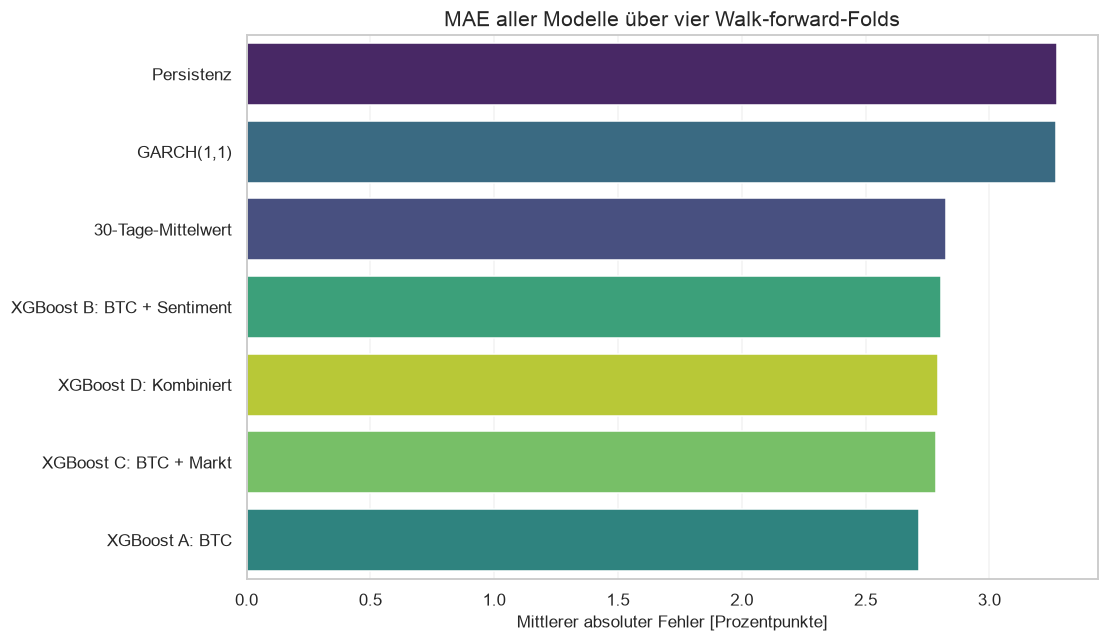

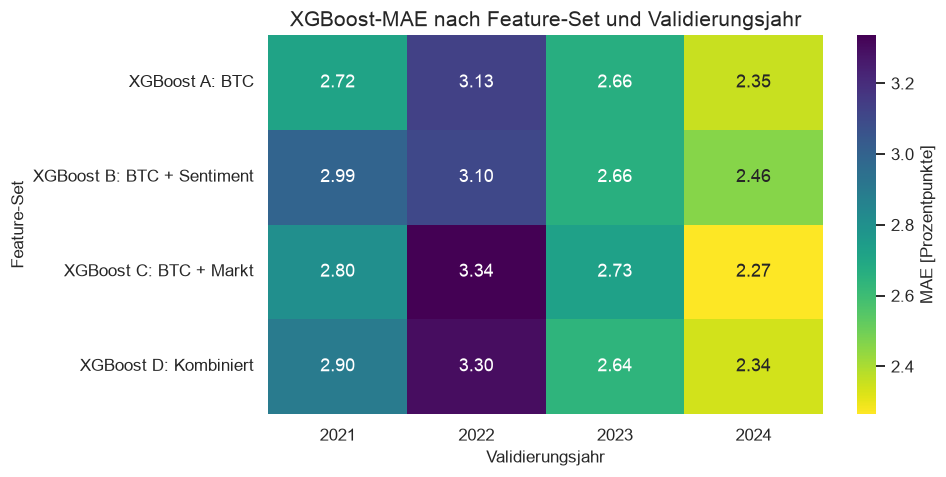

In [35]:
# Plot pooled MAE for all models on a zero-based axis
mae_plot_data = all_overall_metrics.sort_values("MAE", ascending=False).copy()
mae_plot_data["MAE [%P]"] = mae_plot_data["MAE"] * 100
all_model_palette = {model_name: model_palette[model_name] for model_name in all_model_columns}

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=mae_plot_data,
    y="Modell",
    x="MAE [%P]",
    hue="Modell",
    palette=all_model_palette,
    legend=False,
    ax=ax,
)
ax.set_title("MAE aller Modelle über vier Walk-forward-Folds")
ax.set_xlabel("Mittlerer absoluter Fehler [Prozentpunkte]")
ax.set_ylabel("")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.subplots_adjust(left=0.28)
plt.show()

# Compare XGBoost stability across years with one compact heatmap
xgboost_mae_heatmap = (
    xgboost_fold_metrics.assign(**{"MAE [%P]": xgboost_fold_metrics["MAE"] * 100})
    .pivot(index="Modell", columns="Fold", values="MAE [%P]")
)
xgboost_mae_heatmap.columns = [column.replace("Validation ", "") for column in xgboost_mae_heatmap.columns]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(
    xgboost_mae_heatmap,
    cmap="viridis_r",
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "MAE [Prozentpunkte]"},
    ax=ax,
)
ax.set_title("XGBoost-MAE nach Feature-Set und Validierungsjahr")
ax.set_xlabel("Validierungsjahr")
ax.set_ylabel("Feature-Set")
fig.tight_layout()
plt.show()

### 9.4 Unsicherheit der MAE-Unterschiede

#### Erklärung

Der kleinste beobachtete MAE beweist noch keine stabile Überlegenheit. Wir
vergleichen deshalb XGBoost BTC-only paarweise mit dem 30-Tage-Mittelwert und
der Persistenz. Für jeden Prognoseursprung berechnen wir die Differenz der
absoluten Fehler:

$$
d_t = |y_t - \hat{y}_{t,\mathrm{XGB}}|
      - |y_t - \hat{y}_{t,\mathrm{Referenz}}|,
\qquad
\Delta\mathrm{MAE} = \frac{1}{n}\sum_{t=1}^{n} d_t.
$$

Negative Werte sprechen für XGBoost. Ein Moving-Block-Bootstrap zieht
innerhalb jedes Validierungsjahres Blöcke von vier aufeinanderfolgenden
Prognoseursprüngen. Damit berücksichtigen wir lokale zeitliche Abhängigkeit,
ohne Beobachtungen zwischen den Jahresfolds zu vermischen. Wir verwenden
20.000 reproduzierbare Ziehungen und berichten das 95%-Intervall.

In [36]:
# Quantify paired MAE uncertainty while preserving local temporal dependence
def paired_moving_block_bootstrap(
    differences,
    fold_labels,
    block_length=4,
    n_bootstrap=20_000,
    seed=RANDOM_SEED,
):
    rng = np.random.default_rng(seed)
    bootstrap_sums = np.zeros(n_bootstrap)
    total_observations = 0

    # Resample contiguous blocks separately inside every validation year
    for fold_name in pd.unique(fold_labels):
        fold_values = np.asarray(differences[fold_labels == fold_name], dtype=float)
        effective_block_length = min(block_length, len(fold_values))
        blocks_per_sample = int(np.ceil(len(fold_values) / effective_block_length))
        maximum_start = len(fold_values) - effective_block_length
        block_starts = rng.integers(
            0,
            maximum_start + 1,
            size=(n_bootstrap, blocks_per_sample),
        )
        block_offsets = np.arange(effective_block_length)
        sampled_indices = (
            block_starts[..., None] + block_offsets
        ).reshape(n_bootstrap, -1)[:, : len(fold_values)]
        bootstrap_sums += fold_values[sampled_indices].sum(axis=1)
        total_observations += len(fold_values)

    return bootstrap_sums / total_observations


xgboost_absolute_error = (
    prediction_table["actual"] - prediction_table["XGBoost A: BTC"]
).abs()
uncertainty_rows = []

for reference_model in ["30-Tage-Mittelwert", "Persistenz"]:
    reference_absolute_error = (
        prediction_table["actual"] - prediction_table[reference_model]
    ).abs()
    paired_differences = xgboost_absolute_error - reference_absolute_error
    bootstrap_differences = paired_moving_block_bootstrap(
        paired_differences.to_numpy(),
        prediction_table["fold"].to_numpy(),
    )
    confidence_low, confidence_high = np.quantile(
        bootstrap_differences,
        [0.025, 0.975],
    )

    uncertainty_rows.append(
        {
            "Vergleich": f"XGBoost A: BTC minus {reference_model}",
            "MAE-Differenz [%P]": paired_differences.mean() * 100,
            "95%-Untergrenze [%P]": confidence_low * 100,
            "95%-Obergrenze [%P]": confidence_high * 100,
            "XGBoost gewinnt Ursprünge [%]": (paired_differences < 0).mean() * 100,
            "Intervall vollständig unter 0": confidence_high < 0,
        }
    )

uncertainty_results = pd.DataFrame(uncertainty_rows)
display(uncertainty_results.round(3))

xgb_vs_mean = uncertainty_results.iloc[0]
xgb_vs_persistence = uncertainty_results.iloc[1]
display(
    Markdown(
        f'''
#### Interpretation

XGBoost BTC-only senkt den beobachteten MAE gegenüber dem 30-Tage-Mittelwert
um **{-xgb_vs_mean["MAE-Differenz [%P]"]:.3f} Prozentpunkte**. Das
95%-Bootstrap-Intervall reicht jedoch von
**{xgb_vs_mean["95%-Untergrenze [%P]"]:.3f}** bis
**{xgb_vs_mean["95%-Obergrenze [%P]"]:.3f} Prozentpunkten** und enthält null.
Der kleine Vorsprung ist damit im Entwicklungszeitraum nicht stabil
abgesichert.

Gegenüber Persistenz liegt das Intervall von
**{xgb_vs_persistence["95%-Untergrenze [%P]"]:.3f}** bis
**{xgb_vs_persistence["95%-Obergrenze [%P]"]:.3f} Prozentpunkten** vollständig
unter null. Hier ist die Verbesserung deutlich robuster. Der Bootstrap ist
eine Unsicherheitsanalyse des Backtests, aber kein Beweis für zukünftige
Performance; entscheidend bleibt der einmalig geöffnete Holdout.
'''
    )
)

,Vergleich,MAE-Differenz [%P],95%-Untergrenze [%P],95%-Obergrenze [%P],XGBoost gewinnt Ursprünge [%],Intervall vollständig unter 0
0,XGBoost A: BTC minus 30-Tage-Mittelwert,-0.109,-0.309,0.123,54.327,False
1,XGBoost A: BTC minus Persistenz,-0.559,-0.924,-0.301,60.096,True



#### Interpretation

XGBoost BTC-only senkt den beobachteten MAE gegenüber dem 30-Tage-Mittelwert
um **0.109 Prozentpunkte**. Das
95%-Bootstrap-Intervall reicht jedoch von
**-0.309** bis
**0.123 Prozentpunkten** und enthält null.
Der kleine Vorsprung ist damit im Entwicklungszeitraum nicht stabil
abgesichert.

Gegenüber Persistenz liegt das Intervall von
**-0.924** bis
**-0.301 Prozentpunkten** vollständig
unter null. Hier ist die Verbesserung deutlich robuster. Der Bootstrap ist
eine Unsicherheitsanalyse des Backtests, aber kein Beweis für zukünftige
Performance; entscheidend bleibt der einmalig geöffnete Holdout.


### 9.5 Feature Importance

#### Erklärung

Für das kombinierte Feature-Set mitteln wir die Gain-Importance über alle 208
neu geschätzten Modelle. Gain misst, wie stark ein Feature die Zielfunktion
beim Aufteilen von Bäumen verbessert. Die Werte zeigen Modellnutzung, aber
keine Kausalität und wegen korrelierter Volatilitätsfeatures auch keine
eindeutige ökonomische Rangfolge.

,Mittlere Importance,Standardabweichung
rv_30,0.1008,0.0151
rv_14,0.0756,0.0199
btc_volume_log,0.0494,0.0098
rv_7_lag_7,0.0473,0.0084
rv_7_lag_1,0.0457,0.0103
nasdaq_change_14d,0.0402,0.0040
fear_greed,0.0402,0.0092
btc_high_low_range,0.0400,0.0041
fear_greed_lag_1,0.0398,0.0074
vix_close,0.0367,0.0047


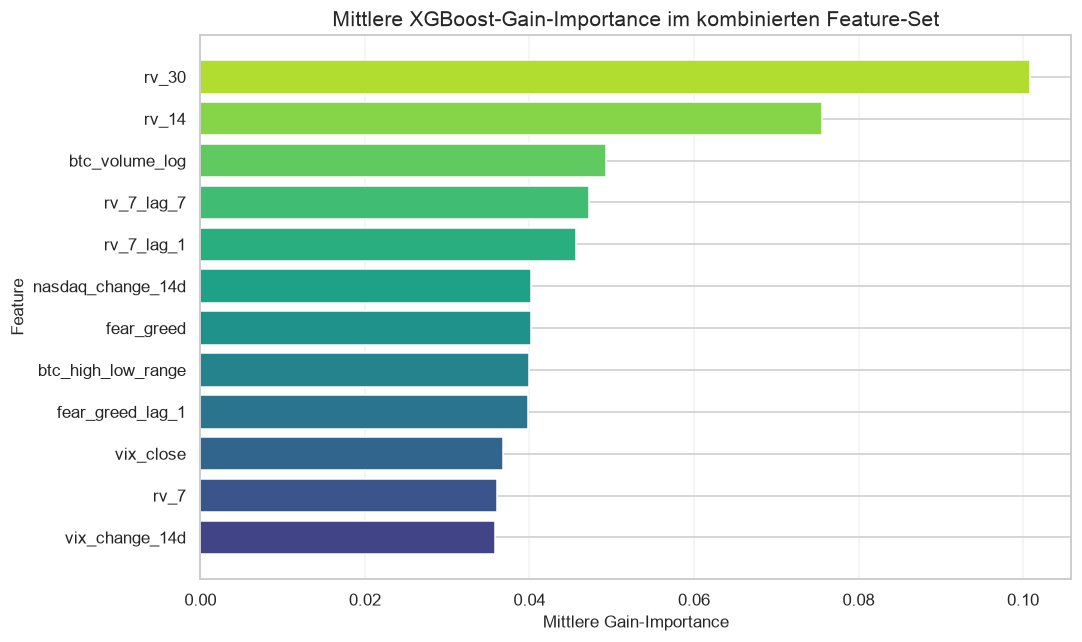

In [37]:
# Average gain importance across every combined walk-forward model
importance_summary = pd.DataFrame(
    {
        "Mittlere Importance": combined_feature_importance.mean(),
        "Standardabweichung": combined_feature_importance.std(),
    }
).sort_values("Mittlere Importance", ascending=False)
top_feature_importance = importance_summary.head(12).sort_values(
    "Mittlere Importance"
)

display(importance_summary.head(12).round(4))

fig, ax = plt.subplots(figsize=(10, 6))
importance_colors = [
    VIRIDIS(position) for position in np.linspace(0.20, 0.88, len(top_feature_importance))
]
ax.barh(
    top_feature_importance.index,
    top_feature_importance["Mittlere Importance"],
    color=importance_colors,
)
ax.set_title("Mittlere XGBoost-Gain-Importance im kombinierten Feature-Set")
ax.set_xlabel("Mittlere Gain-Importance")
ax.set_ylabel("Feature")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

In [38]:
# Derive the interpretation only from executed validation results
best_overall_row = all_overall_metrics.iloc[0]
best_xgboost_row = (
    all_overall_metrics[
        all_overall_metrics["Modell"].isin(xgboost_model_columns)
    ]
    .sort_values("MAE")
    .iloc[0]
)
btc_only_row = all_overall_metrics.loc[
    all_overall_metrics["Modell"] == "XGBoost A: BTC"
].iloc[0]
combined_row = all_overall_metrics.loc[
    all_overall_metrics["Modell"] == "XGBoost D: Kombiniert"
].iloc[0]

best_xgboost_improvement = (
    best_xgboost_row["MAE-Verbesserung ggü. Persistenz"] * 100
)
combined_vs_btc_improvement = 100 * (
    1 - combined_row["MAE"] / btc_only_row["MAE"]
)
top_feature_name = importance_summary.index[0]

# Compare combined and BTC-only performance separately by market regime
xgboost_fold_mae = xgboost_fold_metrics.pivot(
    index="Fold",
    columns="Modell",
    values="MAE",
)
xgboost_fold_mae["Kombiniert ggü. BTC-only [%]"] = 100 * (
    1
    - xgboost_fold_mae["XGBoost D: Kombiniert"]
    / xgboost_fold_mae["XGBoost A: BTC"]
)
combined_better_years = [
    fold.replace("Validation ", "")
    for fold, value in xgboost_fold_mae["Kombiniert ggü. BTC-only [%]"].items()
    if value > 0
]
combined_worse_years = [
    fold.replace("Validation ", "")
    for fold, value in xgboost_fold_mae["Kombiniert ggü. BTC-only [%]"].items()
    if value <= 0
]

display(
    xgboost_fold_mae[["Kombiniert ggü. BTC-only [%]"]]
    .rename_axis("Validierungsfold")
    .round(2)
)

display(
    Markdown(
        f'''
#### Interpretation

Das beste XGBoost-Feature-Set ist **{best_xgboost_row["Modell"]}** mit einem
MAE von **{best_xgboost_row["MAE"] * 100:.3f} Prozentpunkten**. Gegenüber
Persistenz entspricht dies einer Verbesserung von
**{best_xgboost_improvement:.1f}%**. Das kombinierte Set verändert den MAE
gegenüber BTC-only um **{combined_vs_btc_improvement:+.1f}%**. Der negative
Gesamtwert bedeutet, dass die externen Variablen in dieser Konfiguration über
alle vier Folds keinen stabilen Zusatznutzen liefern.

Die Fold-Ergebnisse zeigen jedoch keinen durchgehend schädlichen Effekt: Das
kombinierte Set ist in **{", ".join(combined_better_years)}** leicht besser,
in **{", ".join(combined_worse_years)}** dagegen schlechter als BTC-only.
Das spricht für regimeabhängige Beziehungen. VIX, DXY, Nasdaq oder Sentiment
können in einzelnen Marktphasen helfen, aber ein über alle Jahre stabiles
Signal ist nicht erkennbar.

Eine plausible Erklärung ist, dass die BTC-Features das
Volatilitätsclustering bereits direkt erfassen. Die zusätzlichen Variablen
sind teilweise redundant, zeitlich weniger aktuell oder selbst von Bitcoin
beeinflusst. Zusammen mit 32 statt 18 Features und einer begrenzten
Trainingsmenge erhöht dies die Gefahr, instabile Muster zu lernen. Das feste
Parameterset hält den Vergleich fair, könnte grössere Feature-Sets aber nicht
optimal regularisieren.

Über alle bisherigen Modelle erzielt **{best_overall_row["Modell"]}** den
niedrigsten beobachteten MAE. Der kleine Vorsprung gegenüber dem
30-Tage-Mittelwert ist laut Block-Bootstrap jedoch nicht stabil abgesichert. Im kombinierten XGBoost-Modell besitzt **`{top_feature_name}`** die
höchste mittlere Gain-Importance. Dass externe Features in der Rangliste
auftauchen, widerspricht dem Gesamtergebnis nicht: Importance zeigt Nutzung,
nicht robuste Verbesserung oder Kausalität. Wir schliessen daher nicht, dass
die Zusatzinformationen nutzlos sind, sondern dass ihr zusätzlicher
Prognosewert im Entwicklungszeitraum nicht stabil genug ist. Der finale
Holdout bleibt weiterhin unangetastet.
'''
    )
)

Modell,Kombiniert ggü. BTC-only [%]
Validierungsfold,
Validation 2021,-6.60
Validation 2022,-5.49
Validation 2023,0.98
Validation 2024,0.66



#### Interpretation

Das beste XGBoost-Feature-Set ist **XGBoost A: BTC** mit einem
MAE von **2.716 Prozentpunkten**. Gegenüber
Persistenz entspricht dies einer Verbesserung von
**17.1%**. Das kombinierte Set verändert den MAE
gegenüber BTC-only um **-2.8%**. Der negative
Gesamtwert bedeutet, dass die externen Variablen in dieser Konfiguration über
alle vier Folds keinen stabilen Zusatznutzen liefern.

Die Fold-Ergebnisse zeigen jedoch keinen durchgehend schädlichen Effekt: Das
kombinierte Set ist in **2023, 2024** leicht besser,
in **2021, 2022** dagegen schlechter als BTC-only.
Das spricht für regimeabhängige Beziehungen. VIX, DXY, Nasdaq oder Sentiment
können in einzelnen Marktphasen helfen, aber ein über alle Jahre stabiles
Signal ist nicht erkennbar.

Eine plausible Erklärung ist, dass die BTC-Features das
Volatilitätsclustering bereits direkt erfassen. Die zusätzlichen Variablen
sind teilweise redundant, zeitlich weniger aktuell oder selbst von Bitcoin
beeinflusst. Zusammen mit 32 statt 18 Features und einer begrenzten
Trainingsmenge erhöht dies die Gefahr, instabile Muster zu lernen. Das feste
Parameterset hält den Vergleich fair, könnte grössere Feature-Sets aber nicht
optimal regularisieren.

Über alle bisherigen Modelle erzielt **XGBoost A: BTC** den
niedrigsten beobachteten MAE. Der kleine Vorsprung gegenüber dem
30-Tage-Mittelwert ist laut Block-Bootstrap jedoch nicht stabil abgesichert. Im kombinierten XGBoost-Modell besitzt **`rv_30`** die
höchste mittlere Gain-Importance. Dass externe Features in der Rangliste
auftauchen, widerspricht dem Gesamtergebnis nicht: Importance zeigt Nutzung,
nicht robuste Verbesserung oder Kausalität. Wir schliessen daher nicht, dass
die Zusatzinformationen nutzlos sind, sondern dass ihr zusätzlicher
Prognosewert im Entwicklungszeitraum nicht stabil genug ist. Der finale
Holdout bleibt weiterhin unangetastet.


## 10. Zwischenfazit und nächste Schritte

### Erklärung

Wir verfügen nun über eine qualitätsgeprüfte, leakage-bewusste
Modelling-Tabelle und einen Walk-forward-Vergleich von naiven Baselines,
GARCH(1,1) und vier XGBoost-Feature-Sets. BTC-only liefert den niedrigsten beobachteten MAE, sein kleiner Vorsprung
gegenüber dem 30-Tage-Mittelwert ist im Block-Bootstrap aber nicht stabil
abgesichert. Externe Markt- und Sentimentvariablen helfen in
einzelnen Jahren, zeigen über alle vier Validierungsjahre aber keinen stabilen
Zusatznutzen.

### Code und Ergebnis

Die Datenaufbereitung, Fold-Erzeugung, Prognosen und Metriken bleiben
vollständig in diesem Notebook sichtbar. Die reproduzierbare Tabelle unter
`data/processed/bitcoin_volatility_modeling_table.csv` bleibt ein lokales
Zwischenergebnis und wird nicht auf GitHub versioniert.

### Interpretation

Wir behalten den fehlenden stabilen Zusatznutzen als Ergebnis bei, statt durch
umfangreiches Tuning nachträglich einen Vorteil der externen Features zu
erzwingen. Als nächsten Abschnitt ergänzen wir Chronos-2 mit `rv_7` als
Kontext und Forecast-Schritt 7 als Zielprognose. Danach erstellen wir den
gemeinsamen Modellvergleich und legen die endgültige Methode fest. Erst dann
öffnen wir den Holdout ab 2025 einmalig für die finale Evaluation.

Lightning verwenden wir nicht, solange kein eigenes PyTorch-Modell trainiert
wird. Für Zero-Shot-Inferenz mit Chronos-2 genügt die direkte Modell-API.